# Laplace, profile likelihood e DALI
## Altura, volume e geometria da posterior
**Igor Stellet · Estatística Bayesiana · 2026.2**

Ideia do notebook: **quanto perdemos quando representamos uma distribuição apenas pelo comportamento perto de um máximo?** A resposta depende tanto da altura do pico quanto de sua largura, dos outros picos, da prior e das coordenadas escolhidas.

O que será feito:

1. Deduzir Laplace e distinguir curvatura observada de informação de Fisher.
2. Separar marginalização, profile likelihood e profile da posterior.
3. Reconstruir a situação do slide 95 e executar o modelo dos slides 96–97.
4. Localizar a prior nos efeitos de volume, com um modelo gerador explícito.
5. Construir a passagem do slide 104 até singlet, doublet e triplet DALI.
6. Investigar erros de truncamento, parametrização e integração das aproximações.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate, optimize, linalg
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':220,'font.size':11,
    'axes.titlesize':12,'legend.fontsize':9,'grid.alpha':.2,
    'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42})
AZUL,VERDE,OURO,ROXO,VERMELHO='#2878B5','#27856D','#B58618','#8055A3','#BD5254'
SALVAR_ARQUIVOS=False
BASE=Path.cwd();PF=BASE/'figuras'/'laplace_profile_DALI';PT=BASE/'tabelas'/'laplace_profile_DALI'
checks=[];figuras=[]
def verificar(nome,condicao):
    if not np.all(condicao):raise AssertionError(nome)
    checks.append(nome)
def figura(fig,nome):
    figuras.append(nome)
    if SALVAR_ARQUIVOS:
        PF.mkdir(parents=True,exist_ok=True)
        for ext in ('png','pdf'):fig.savefig(PF/f'{nome}.{ext}',bbox_inches='tight')
    plt.show();plt.close(fig)
def tabela(df,nome=None,casas=5):
    display(df.round(casas))
    if SALVAR_ARQUIVOS and nome:
        PT.mkdir(parents=True,exist_ok=True);df.to_csv(PT/f'{nome}.csv',index=False)
def trap(y,x,axis=-1):return integrate.trapezoid(y,x=x,axis=axis)
def normalizar(y,x):
    y=np.asarray(y,float);z=trap(y,x)
    if not np.isfinite(z) or z<=0:raise ValueError('Integral inválida.')
    return y/z
def normalizar_log(logy,x):
    return normalizar(np.exp(np.asarray(logy)-np.max(logy)),x)
def tv(p,q,x):return .5*trap(np.abs(p-q),x)
def resumo_1d(p,x):
    media=trap(p*x,x);var=trap(p*(x-media)**2,x)
    return {'Moda':x[np.argmax(p)],'Média':media,'Desvio':np.sqrt(var)}
def norm2(raw,x,y):
    z=trap(trap(raw,y,axis=1),x)
    return raw/z,z
def pesos_trap(x):
    x=np.asarray(x);w=np.empty(len(x));w[0]=(x[1]-x[0])/2;w[-1]=(x[-1]-x[-2])/2
    w[1:-1]=(x[2:]-x[:-2])/2;return w
def niveis_hpd(pdf,x,y,prob=(.6827,.9545)):
    massas=pdf*np.outer(pesos_trap(x),pesos_trap(y))
    ordem=np.argsort(-pdf.ravel());acum=np.cumsum(massas.ravel()[ordem])
    return np.sort([pdf.ravel()[ordem[min(np.searchsorted(acum,p),len(ordem)-1)]] for p in prob])
print('Exportação opcional:',SALVAR_ARQUIVOS)

Exportação opcional: False


## 1. O que Laplace aproxima?

Definimos uma função positiva ainda não normalizada,
$$
g(\vartheta)=\mathcal L(D\mid\vartheta)\pi_0(\vartheta),
\quad \ell(\vartheta)=\log g(\vartheta),
\quad Z=\int g(\vartheta)\,d\vartheta,
\quad p(\vartheta\mid D)=g(\vartheta)/Z.
$$
Suponha um máximo **interior** $\hat\vartheta$, onde $\nabla\ell=0$. Com $\delta=\vartheta-\hat\vartheta$, a expansão é
$$
\ell(\hat\vartheta+\delta)
=\ell(\hat\vartheta)+
\underbrace{\nabla\ell(\hat\vartheta)^T\delta}_{0}
+\frac12\delta^T\nabla^2\ell(\hat\vartheta)\delta+O(\|\delta\|^3).
$$
Definimos a curvatura positiva $H=-\nabla^2\ell(\hat\vartheta)$. Se $H$ é positiva definida,
$$
g(\vartheta)\approx g(\hat\vartheta)
\exp[-\tfrac12\delta^TH\delta].
$$
**Laplace é uma aproximação de integrais baseada nessa vizinhança gaussiana.** Primeiro aproximamos o logaritmo; depois integramos a exponencial resultante. Não substituímos uma integral simplesmente pelo valor máximo do integrando: falta o volume em torno desse máximo.

### 1.1 A integral dos slides 92–93, sem saltar a mudança de variáveis

Pelo teorema dos eixos principais, $H=O\Lambda O^T$, onde as colunas de $O$ são autovetores ortonormais e $\Lambda=\operatorname{diag}(\lambda_1,\ldots,\lambda_k)$, com $\lambda_i>0$. Faça $\delta=Ox$. Então
$$
\delta^TH\delta=x^T\Lambda x=\sum_i\lambda_i x_i^2,
\qquad d\delta=|\det O|\,dx=dx.
$$
Uma matriz ortogonal pode ter determinante $+1$ **ou** $-1$; o Jacobiano da medida usa o módulo, que vale 1. Cada integral separada pode ser transformada por $u_i=\sqrt{\lambda_i}x_i$:
$$
\int_{-\infty}^{\infty}e^{-\lambda_i x_i^2/2}dx_i
=\lambda_i^{-1/2}\int e^{-u_i^2/2}du_i
=\sqrt{2\pi/\lambda_i}.
$$
Multiplicando as $k$ integrais e usando $\det H=\prod_i\lambda_i$,
$$
\boxed{Z_{\rm Lap}=g(\hat\vartheta)
\frac{(2\pi)^{k/2}}{\sqrt{\det H}}.}
$$
O fator $V_{\rm eff}=(2\pi)^{k/2}/\sqrt{\det H}$ tem unidades de volume paramétrico. Autovalores grandes significam direções estreitas; autovalores pequenos significam direções largas. A posterior aproximada é $\mathcal N(\hat\vartheta,H^{-1})$.

Estender o domínio real da prior para todo $\mathbb R^k$ é uma etapa adicional: funciona quando a massa relevante está longe das bordas. Direções planas, picos relevantes omitidos e caudas extensas podem invalidar a aproximação. Sob condições regulares de concentração, a integral admite uma expansão assintótica; ter “muitos dados” sem identificabilidade ou sem um máximo interior não basta.

,Autovalor,Largura 1/sqrt(λ)
0,1.43795,0.83393
1,4.56205,0.46819


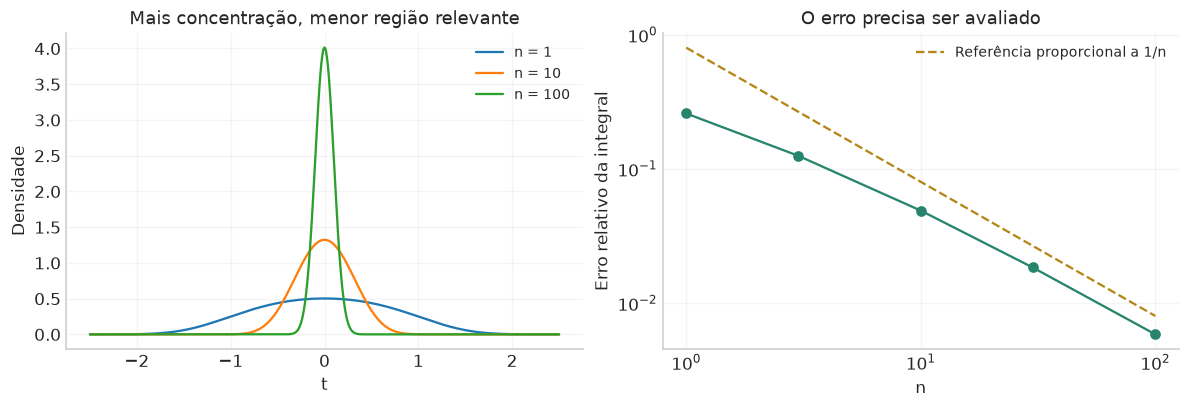

,n,Integral exata,Laplace,Erro relativo
0,1,1.99160,2.50663,0.25860
1,3,1.28621,1.44720,0.12517
2,10,0.75579,0.79267,0.04880
3,30,0.44938,0.45765,0.01839
4,100,0.24921,0.25066,0.00584


In [2]:
# Verificação numérica da integral gaussiana e de sua geometria.
H_demo=np.array([[4.,1.2],[1.2,2.]])
autoval,O=np.linalg.eigh(H_demo)
I_prod=np.prod([integrate.quad(lambda z:np.exp(-lam*z*z/2),-np.inf,np.inf)[0] for lam in autoval])
I_det=(2*np.pi)/np.sqrt(np.linalg.det(H_demo))
verificar('Integral gaussiana: autovalores e determinante',np.isclose(I_prod,I_det))
verificar('Mudança ortogonal preserva medida',np.isclose(abs(np.linalg.det(O)),1))
tabela(pd.DataFrame({'Autovalor':autoval,'Largura 1/sqrt(λ)':1/np.sqrt(autoval)}),'eixos_laplace')

# Uma integral não gaussiana, com máximo único, fica mais local à medida que n cresce.
# n é um parâmetro de concentração neste exemplo matemático.
ns=np.array([1,3,10,30,100]);vals=[]
fig,ax=plt.subplots(1,2,figsize=(10.7,3.6),constrained_layout=True)
tt=np.linspace(-2.5,2.5,1000)
for n in ns:
    exato=integrate.quad(lambda t:np.exp(-n*(t*t/2+.2*t**4)),-np.inf,np.inf)[0]
    aprox=np.sqrt(2*np.pi/n)
    vals.append({'n':n,'Integral exata':exato,'Laplace':aprox,'Erro relativo':aprox/exato-1})
    if n in [1,10,100]:ax[0].plot(tt,np.exp(-n*(tt*tt/2+.2*tt**4))/exato,label=f'n = {n}')
ax[0].set(xlabel='t',ylabel='Densidade',title='Mais concentração, menor região relevante');ax[0].legend()
ax[1].loglog(ns,[v['Erro relativo'] for v in vals],'-o',color=VERDE)
ax[1].loglog(ns,.8/ns,'--',color=OURO,label='Referência proporcional a 1/n')
ax[1].set(xlabel='n',ylabel='Erro relativo da integral',title='O erro precisa ser avaliado');ax[1].legend()
figura(fig,'01_concentracao_laplace')
tabela(pd.DataFrame(vals),'laplace_concentracao')
verificar('Laplace melhora com concentração no exemplo',vals[-1]['Erro relativo']<vals[0]['Erro relativo'])

## 2. Laplace e Fisher: parentes próximos, papéis diferentes

Nos slides, $F$ também designa a curvatura local do logaritmo. Para evitar confusão, vamos distinguir:

| Objeto | Definição | O que descreve |
|---|---|---|
| Curvatura observada da posterior | $H=-\nabla^2[\log\mathcal L+\log\pi_0]$ no MAP | Este conjunto de dados e esta prior |
| Fisher esperada | $F_{ab}=\mathbb E_{D\mid\vartheta}[-\partial_a\partial_b\log\mathcal L]$ | Informação média de repetições do experimento |
| Aproximação gaussiana de Fisher | Usar uma forma quadrática com $F$ ou com uma curvatura observada, conforme a convenção | Uma descrição local da distribuição |
| Método de Laplace | Integrar a exponencial da expansão quadrática local | Evidências, marginais e outras integrais |

Se “Fisher” já significa a Hessiana observada da **mesma posterior**, a gaussiana de partida de Laplace é a mesma. Não existe aí uma nova expansão. Já substituir a Hessiana observada pela Fisher **esperada** é outra aproximação.

Para dados gaussianos com $C$ fixa,
$$
\log\mathcal L=\text{constante}-\tfrac12r^TWr,\qquad
r=D-\mu,\quad J_{ia}=\partial_a\mu_i.
$$
Como $\partial_a r=-\mu_{,a}$, obtemos, derivando duas vezes,
$$
\partial_a\log\mathcal L=\mu_{,a}^TWr,
\qquad
H^{\mathcal L}_{ab}=
\underbrace{\mu_{,a}^TW\mu_{,b}}_{F_{ab}}
-r^TW\mu_{,ab}.
$$
No modelo gerador, $\mathbb E[r]=0$, então a Fisher esperada é $J^TWJ$. Para a posterior,
$$
H_{ab}=H^{\mathcal L}_{ab}-\partial_a\partial_b\log\pi_0.
$$
O termo de resíduo pode sobreviver no melhor ajuste: $J^TWr=0$ não implica $r=0$. Uma prior gaussiana soma sua precisão a $H^\mathcal L$; uma prior uniforme só é localmente constante **dentro** de seu suporte.

### Exemplo: duas medidas de um único parâmetro

Considere $\mu(t)=(t,t^2)$, $D=(1,0)$, erros independentes de desvio $s=0{,}5$ e prior uniforme em $[-3,3]$. Assim,
$$
\Psi(t)=-\log g+\text{constante}
=\frac{(1-t)^2+t^4}{2s^2}.
$$
O máximo satisfaz $2\hat t^3+\hat t-1=0$.
A Fisher é $F=(1+4\hat t^2)/s^2$, enquanto
$H=(1+6\hat t^2)/s^2$. A diferença vem da curvatura da parábola no espaço dos dados e do resíduo que permanece no ajuste.

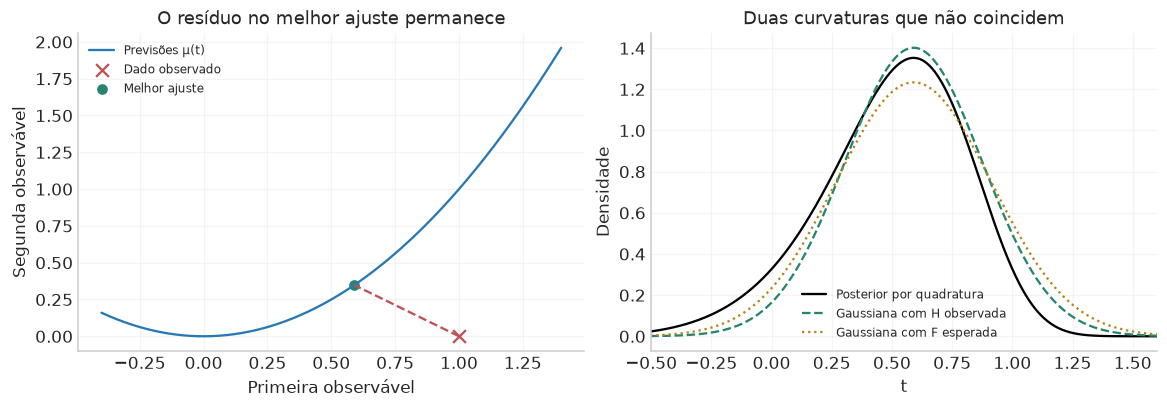

,Curvatura,Valor,Largura local,TV para a posterior
0,H observada,12.34745,0.28458,0.08967
1,F esperada,9.56497,0.32334,0.09829


In [3]:
s_obs=.5
t_hat=optimize.brentq(lambda t:2*t**3+t-1,0,1)
F_obs=(1+4*t_hat**2)/s_obs**2
H_obs=(1+6*t_hat**2)/s_obs**2
tt_obs=np.linspace(-3,3,1400)
psi_obs=lambda t:((1-t)**2+t**4)/(2*s_obs**2)
p_obs=normalizar_log(-psi_obs(tt_obs),tt_obs)
p_H=normalizar(stats.norm.pdf(tt_obs,t_hat,1/np.sqrt(H_obs)),tt_obs)
p_F=normalizar(stats.norm.pdf(tt_obs,t_hat,1/np.sqrt(F_obs)),tt_obs)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.6),constrained_layout=True)
track=np.linspace(-.4,1.4,500)
ax[0].plot(track,track**2,color=AZUL,label='Previsões μ(t)')
ax[0].scatter([1],[0],marker='x',s=70,color=VERMELHO,label='Dado observado')
ax[0].scatter([t_hat],[t_hat*t_hat],color=VERDE,label='Melhor ajuste')
ax[0].plot([1,t_hat],[0,t_hat*t_hat],'--',color=VERMELHO)
ax[0].set(xlabel='Primeira observável',ylabel='Segunda observável',title='O resíduo no melhor ajuste permanece');ax[0].legend(fontsize=8)
ax[1].plot(tt_obs,p_obs,color='black',label='Posterior por quadratura')
ax[1].plot(tt_obs,p_H,'--',color=VERDE,label='Gaussiana com H observada')
ax[1].plot(tt_obs,p_F,':',color=OURO,label='Gaussiana com F esperada')
ax[1].set(xlim=(-.5,1.6),xlabel='t',ylabel='Densidade',title='Duas curvaturas que não coincidem');ax[1].legend(fontsize=8)
figura(fig,'02_fisher_observada_laplace')
tabela(pd.DataFrame({'Curvatura':['H observada','F esperada'],'Valor':[H_obs,F_obs],
    'Largura local':[1/np.sqrt(H_obs),1/np.sqrt(F_obs)],
    'TV para a posterior':[tv(p_H,p_obs,tt_obs),tv(p_F,p_obs,tt_obs)]}),'curvaturas_observadas')
verificar('Resíduo distingue H de F',H_obs>F_obs)

### 2.1 A prior na evidência: volume posterior em relação ao volume prévio

Com uma prior uniforme de volume $V_0$, longe das bordas,
$$
Z_{\rm Lap}\approx \mathcal L(\hat\vartheta)
\frac{V_{\rm eff}}{V_0}.
$$
A evidência é uma **média da likelihood sob a prior**. Um bom ajuste que exige uma região minúscula da prior recebe pouco peso nessa média. É a origem do fator de Occam nesse caso; não precisamos inventar uma penalização depois do cálculo.

Para uma medida $y$, erro gaussiano conhecido $\sigma$ e média desconhecida $a\sim U[-A,A]$,
$$
Z(A)=\frac1{2A}\int_{-A}^A
\frac{e^{-(y-a)^2/(2\sigma^2)}}{\sqrt{2\pi}\sigma}\,da
=\frac{\Phi((A-y)/\sigma)-\Phi((-A-y)/\sigma)}{2A},
$$
onde $\Phi$ é a CDF normal padrão. Quando o intervalo cobre toda a likelihood relevante, $Z\simeq1/(2A)$, embora a posterior normalizada de $a$ praticamente não mude. A constante da prior cancela nessa posterior, mas precisa permanecer na evidência.

Esse efeito de amplitude da prior na evidência e o deslocamento de uma marginal por larguras nuisance variáveis são fenômenos relacionados pelo volume, mas são cálculos distintos. Uma evidência pode ter unidades de densidade dos dados; a razão entre evidências para os mesmos dados é adimensional.

## 3. Marginalizar, perfilar e fixar respondem a perguntas diferentes

Com $\theta$ fixo, definimos
$$
m(\theta)=\int g(\theta,\phi)d\phi,\qquad
\hat\phi(\theta)=\arg\max_\phi g(\theta,\phi),\qquad
f(\theta)=g(\theta,\hat\phi(\theta)).
$$
A posterior marginal é $m/\int m\,d\theta$. O profile $f$ retém a **altura** máxima de cada fatia; a marginal retém sua **área ou volume**. Fixar $\phi=\phi_0$ produz outra fatia, $g(\theta,\phi_0)$, sem permitir que o nuisance se reajuste a cada $\theta$.

Convém separar também as definições:

| Operação | Função maximizada | Interpretação |
|---|---|---|
| Profile likelihood | $\mathcal L(D\mid\theta,\phi)$ | Ajuste dos dados com nuisance otimizado |
| Profile da posterior | $\mathcal L\pi_0$ | Altura de uma densidade posterior, dependente da prior |
| Marginal posterior | Integral de $\mathcal L\pi_0$ em $\phi$ | Probabilidade posterior para $\theta$ |

O slide 94 maximiza **prior vezes likelihood**: é o segundo objeto. Os profiles coincidem em forma com prior plana no suporte relevante, mas não em geral. Normalizar um profile para desenhá-lo como curva **não o transforma automaticamente em uma posterior marginal**.

No uso frequentista, pode-se trabalhar com
$$
\lambda(\theta)=\frac{\max_\phi\mathcal L(\theta,\phi)}
{\max_{\theta,\phi}\mathcal L(\theta,\phi)}.
$$
Sob condições regulares e assintóticas, \(-2\log\lambda\) admite a calibração de Wilks por \(\chi^2\) com dimensão igual ao número de parâmetros de interesse fixados. Bordas, não identificabilidade, poucos dados ou múltiplos modos podem exigir calibração por simulação. Integrar áreas sob um profile normalizado não fornece essa garantia de cobertura.

### 3.1 Laplace condicional: a largura tem de ser recalculada em cada fatia

Se $\phi$ tem $r$ componentes, expanda **somente em $\phi$**, mantendo $\theta$ fixo:
$$
\log g(\theta,\hat\phi+\Delta\phi)
\approx \log f(\theta)-\tfrac12\Delta\phi^T
H_{\phi\phi}(\theta)\Delta\phi,
$$
$$
H_{\phi\phi}(\theta)=
-\left.\frac{\partial^2\log g}{\partial\phi\,\partial\phi^T}\right|_{\phi=\hat\phi(\theta)}.
$$
Aplicando a integral anterior a cada fatia,
$$
\boxed{m_{\rm Lap}(\theta)=
f(\theta)\frac{(2\pi)^{r/2}}{\sqrt{\det H_{\phi\phi}(\theta)}}.}
$$
É essa matriz **nuisance com $\theta$ fixo** que aparece no slide 94; não é a Hessiana completa nem a inversa de um bloco marginal. O caminho $\hat\phi(\theta)$ e a curvatura podem variar de modo não linear. Logo, uma marginal de Laplace pode ser assimétrica mesmo que cada integral nuisance seja aproximada por uma gaussiana.

Em logaritmos,
$$
\log m_{\rm Lap}=\log f-\tfrac12\log\det H_{\phi\phi}
+\tfrac r2\log(2\pi).
$$
**Quando usar só o máximo?** Quando essa largura efetiva varia pouco ao longo da região relevante. Ser gaussiana em cada fatia não basta: as gaussianas podem ter larguras diferentes. Se a diferença de $\log V_{\rm eff}(\theta)$ for pequena em toda a região de interesse, desprezá-la afeta pouco a forma normalizada.

### 3.2 Conexão com a marginalização por blocos do capítulo 10

Em uma gaussiana conjunta, escreva sua precisão como
$$
H=\begin{pmatrix}A&B\\B^T&D_\phi\end{pmatrix}.
$$
O expoente é
$$
\frac12\theta^TA\theta+\theta^TB\phi+\frac12\phi^TD_\phi\phi
=\frac12(\phi+D_\phi^{-1}B^T\theta)^TD_\phi
(\phi+D_\phi^{-1}B^T\theta)
+\frac12\theta^T(A-BD_\phi^{-1}B^T)\theta.
$$
O melhor nuisance é $\hat\phi=-D_\phi^{-1}B^T\theta$. Integrar o primeiro termo só multiplica o profile por $(2\pi)^{r/2}/\sqrt{\det D_\phi}$, que é **constante em $\theta$**. Por isso as formas normalizadas de marginal e profile coincidem nesse caso. A precisão marginal é o complemento de Schur $A-BD_\phi^{-1}B^T$, e a covariância marginal é o bloco correspondente de $H^{-1}$.

Já fixar $\phi=0$ deixa a precisão $A$, tipicamente maior: perde-se a liberdade de compensação entre parâmetros. A coincidência entre profile e marginal não significa coincidência com uma fatia fixa.

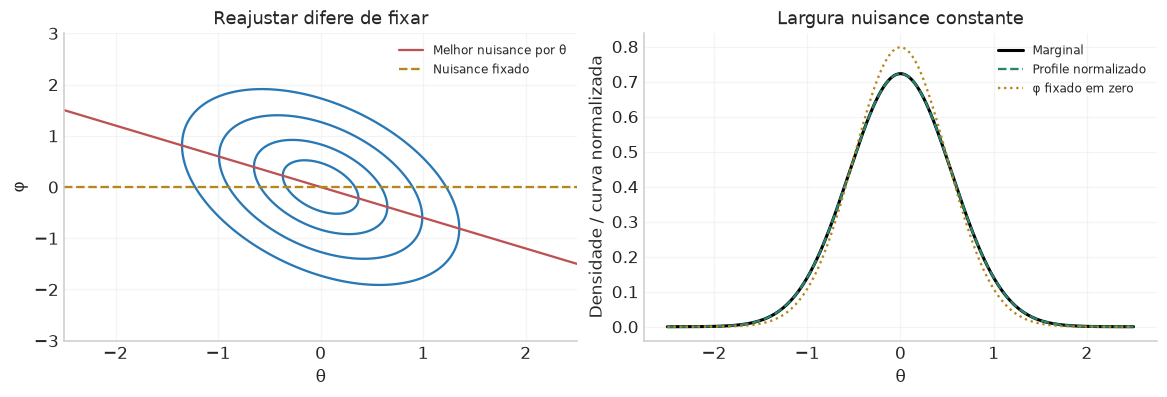

In [4]:
theta_g=np.linspace(-2.5,2.5,800);phi_g=np.linspace(-3,3,800)
Tg,Pg=np.meshgrid(theta_g,phi_g,indexing='ij')
raw_g=np.exp(-.5*(H_demo[0,0]*Tg*Tg+2*H_demo[0,1]*Tg*Pg+H_demo[1,1]*Pg*Pg))
phihat_g=-H_demo[1,0]/H_demo[1,1]*theta_g
schur=H_demo[0,0]-H_demo[0,1]**2/H_demo[1,1]
prof_g=normalizar(np.exp(-.5*schur*theta_g**2),theta_g)
marg_g=normalizar(trap(raw_g,phi_g,axis=1),theta_g)
fixo_g=normalizar(np.exp(-.5*H_demo[0,0]*theta_g**2),theta_g)
verificar('Schur e bloco da covariância coincidem',np.isclose(1/schur,np.linalg.inv(H_demo)[0,0]))
verificar('Profile e marginal gaussianos têm a mesma forma',tv(prof_g,marg_g,theta_g)<1e-4)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
ax[0].contour(theta_g,phi_g,raw_g.T,levels=[.05,.2,.5,.8],colors=AZUL)
ax[0].plot(theta_g,phihat_g,color=VERMELHO,label='Melhor nuisance por θ')
ax[0].axhline(0,color=OURO,ls='--',label='Nuisance fixado')
ax[0].set(xlabel='θ',ylabel='φ',title='Reajustar difere de fixar');ax[0].legend(fontsize=8)
ax[1].plot(theta_g,marg_g,color='black',lw=2,label='Marginal')
ax[1].plot(theta_g,prof_g,'--',color=VERDE,label='Profile normalizado')
ax[1].plot(theta_g,fixo_g,':',color=OURO,label='φ fixado em zero')
ax[1].set(xlabel='θ',ylabel='Densidade / curva normalizada',title='Largura nuisance constante');ax[1].legend(fontsize=8)
figura(fig,'03_schur_profile_marginal')

## 4. Slide 95: um pico alto pode ter pouca massa

O slide apresenta uma figura hipotética, sem fornecer a função que a gerou; o texto correspondente do Gregory também descreve a geometria sem especificar essa função. Faremos uma **reconstrução didática dessa situação**, não uma digitalização dos valores da figura.

Em $0\leq\theta,\phi\leq1$, somamos duas gaussianas independentes em cada componente:
$$
g(\theta,\phi)=
0{,}96\,N(\theta;0{,}45,0{,}15^2)N(\phi;0{,}5,0{,}2^2)
+0{,}04\,N(\theta;0{,}65,0{,}025^2)N(\phi;0{,}5,0{,}02^2).
$$
Cada termo é uma densidade 2D antes de truncarmos no quadrado. Normalizamos a soma no domínio declarado. O primeiro componente é largo e contém quase toda a massa; o segundo é estreito e pode produzir a maior densidade conjunta.

Como ambos são centrados em $\phi=0{,}5$, o profile passa por essa linha. Denote suas alturas por $a(\theta)$ e $b(\theta)$. Em cada fatia,
$$
f=a+b,\qquad
H_{\phi\phi}=
\frac{a/(0{,}2)^2+b/(0{,}02)^2}{a+b}.
$$
A fórmula vem de $g'=0$ em $\phi=0{,}5$ e
$-(\log g)''=-g''/g+(g'/g)^2$. Perto do componente estreito, a curvatura é grande, mas existem asas largas que uma única gaussiana local não descreve bem.

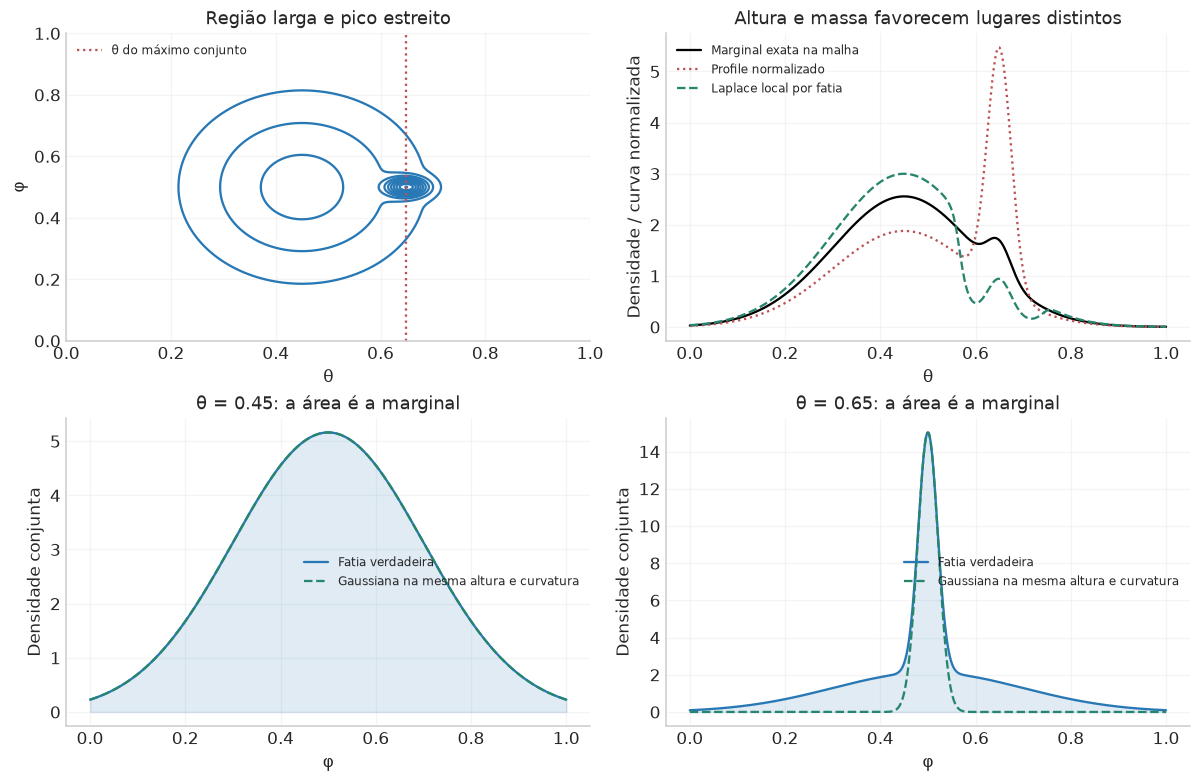

,Curva,Moda,Média,Desvio,TV para marginal
0,Marginal,0.45000,0.45868,0.15111,0.00000
1,Profile normalizado,0.64857,0.50930,0.15518,0.21663
2,Laplace local,0.45000,0.42825,0.14192,0.12791


In [5]:
t95=np.linspace(0,1,701);p95=np.linspace(0,1,801)
Gwide=.96*np.outer(stats.norm.pdf(t95,.45,.15),stats.norm.pdf(p95,.5,.2))
Gnarrow=.04*np.outer(stats.norm.pdf(t95,.65,.025),stats.norm.pdf(p95,.5,.02))
pdf95,Z95=norm2(Gwide+Gnarrow,t95,p95)
altura_w=.96*stats.norm.pdf(t95,.45,.15)*stats.norm.pdf(.5,.5,.2)
altura_n=.04*stats.norm.pdf(t95,.65,.025)*stats.norm.pdf(.5,.5,.02)
prof95=(altura_w+altura_n)/Z95
H95=(altura_w/.2**2+altura_n/.02**2)/(altura_w+altura_n)
marg95=normalizar(trap(pdf95,p95,axis=1),t95)
lap95=normalizar(prof95*np.sqrt(2*np.pi/H95),t95)
normprof95=normalizar(prof95,t95)
fig,ax=plt.subplots(2,2,figsize=(10.8,7),constrained_layout=True)
ax[0,0].contour(t95,p95,pdf95.T,levels=12,colors=AZUL)
ax[0,0].axvline(t95[np.argmax(prof95)],ls=':',color=VERMELHO,label='θ do máximo conjunto')
ax[0,0].set(xlabel='θ',ylabel='φ',title='Região larga e pico estreito');ax[0,0].legend(fontsize=8)
ax[0,1].plot(t95,marg95,color='black',label='Marginal exata na malha')
ax[0,1].plot(t95,normprof95,':',color=VERMELHO,label='Profile normalizado')
ax[0,1].plot(t95,lap95,'--',color=VERDE,label='Laplace local por fatia')
ax[0,1].set(xlabel='θ',ylabel='Densidade / curva normalizada',title='Altura e massa favorecem lugares distintos');ax[0,1].legend(fontsize=8)
for j,t0 in enumerate([.45,.65]):
    k=np.argmin(abs(t95-t0));slice95=pdf95[k]
    gaussian95=prof95[k]*np.exp(-.5*H95[k]*(p95-.5)**2)
    ax[1,j].plot(p95,slice95,color=AZUL,label='Fatia verdadeira')
    ax[1,j].fill_between(p95,slice95,color=AZUL,alpha=.14)
    ax[1,j].plot(p95,gaussian95,'--',color=VERDE,label='Gaussiana na mesma altura e curvatura')
    ax[1,j].set(xlabel='φ',ylabel='Densidade conjunta',title=f'θ = {t95[k]:.2f}: a área é a marginal')
    ax[1,j].legend(fontsize=8)
figura(fig,'04_slide95_altura_volume')
tabela(pd.DataFrame([{'Curva':nome,**resumo_1d(curva,t95),'TV para marginal':tv(curva,marg95,t95)}
    for nome,curva in [('Marginal',marg95),('Profile normalizado',normprof95),('Laplace local',lap95)]]),'slide95_resumo')
verificar('Slide 95: maior altura não determina maior massa',t95[np.argmax(prof95)]>t95[np.argmax(marg95)]+.1)

As duas figuras inferiores mostram exatamente o que a conta de máximo omite. Uma fatia pode ser alta e estreita; outra, baixa e larga. Multiplicar pela largura gaussiana corrige a primeira perda de informação, mas não recupera automaticamente as asas de uma mistura de escalas.

Uma gaussiana ajustada localmente ao topo da soma difere de integrar os dois componentes gaussianos conhecidos separadamente. Como conhecemos a construção desse exemplo, podemos fazer essas integrais separadas exatamente, incluindo a truncagem em \([0,1]\). Em problemas reais nem sempre temos essa decomposição disponível.

## 5. Slides 96–97: a curva com formato beta

O modelo é
$$
f(x;\alpha,\beta)=x^{\alpha-1}(1-x)^{\beta-1},\qquad 0<x<1,\quad\alpha,\beta>1.
$$
Ele é uma **previsão para a média de $y$ em cada $x$**. Seu formato lembra o núcleo de uma distribuição Beta, mas não inclui a constante $1/B(\alpha,\beta)$. Acrescentá-la mudaria o modelo de regressão.

O modelo gerador dos slides é
$$
y_i=f(x_i;6,3)+\varepsilon_i,\qquad
\varepsilon_i\overset{\rm ind}{\sim}N(0,0{,}005^2),\quad i=1,\ldots,12.
$$
Portanto, a distribuição condicional dos dados é gaussiana:
$$
\mathcal L(\alpha,\beta)
=(2\pi\sigma^2)^{-12/2}
\exp\!\left[-\frac1{2\sigma^2}\sum_i
\{y_i-f(x_i;\alpha,\beta)\}^2\right].
$$
Não estamos supondo $x_i$ ou $y_i$ distribuídos como Beta. Os $x_i$ são posições fixas do experimento. Usaremos 12 posições entre 0,05 e 0,95, uma realização de ruído própria e prior uniforme em
$\alpha\in[1{,}05,16]$, $\beta\in[1{,}05,7]$. O slide não fornece os dados numéricos nem a semente; reproduzimos o **procedimento e o modelo**, com todos esses detalhes declarados.

### 5.1 Abrir as derivadas antes de calcular a curvatura

De $\log f=(\alpha-1)\log x+(\beta-1)\log(1-x)$, segue
$$
f_{,\alpha}=f\log x,\quad f_{,\beta}=f\log(1-x),
\quad f_{,\alpha\alpha}=f(\log x)^2.
$$
Mais geralmente,
$$
\frac{\partial^{r+s}f}{\partial\alpha^r\partial\beta^s}
=f(\log x)^r[\log(1-x)]^s.
$$
Para manter $\beta$ e eliminar $\alpha$, minimizamos
$\Psi(\alpha,\beta)=\sum_i(y_i-f_i)^2/(2\sigma^2)\) em \(\alpha$.
Com $r_i=y_i-f_i$, a equação do máximo interior é
$$
0=\partial_\alpha\Psi
=-\sigma^{-2}\sum_i r_i f_{i,\alpha},
$$
e a curvatura condicional **observada** é
$$
H_{\alpha\alpha}(\beta)
=\sigma^{-2}\sum_i
\left[f_{i,\alpha}^2-r_i f_{i,\alpha\alpha}\right]
\quad\text{em }\alpha=\hat\alpha(\beta).
$$
Assim,
$$
m_{\rm Lap}(\beta)\propto
\exp[-\Psi(\hat\alpha(\beta),\beta)]
\sqrt{\frac{2\pi}{H_{\alpha\alpha}(\beta)}}.
$$
Essa é uma sucessão de aproximações **em uma dimensão nuisance**, não uma única gaussiana em todo o plano $(\alpha,\beta)$.

No código, a densidade na malha tem dimensões $(n_\alpha,n_\beta)$, enquanto o vetor de previsões em todos os pontos tem dimensões $(n_\alpha,n_\beta,12)$. Somamos os resíduos ao quadrado no último eixo, o dos dados. Depois integramos no eixo de $\alpha$ para obter a marginal em $\beta$. O argumento de eixo nas integrais explicita qual parâmetro está sendo eliminado.

Para estabilidade, multiplicamos o núcleo da likelihood por $e^{\Psi_{\min}}$ antes da quadratura; esse fator constante cancela ao normalizar a posterior. A variável Z_beta registra a integral desse núcleo reescalado, usada para conferir o refinamento da malha. Para obter a evidência da seção 1 seria necessário restaurar também a normalização da likelihood e a densidade normalizada da prior.

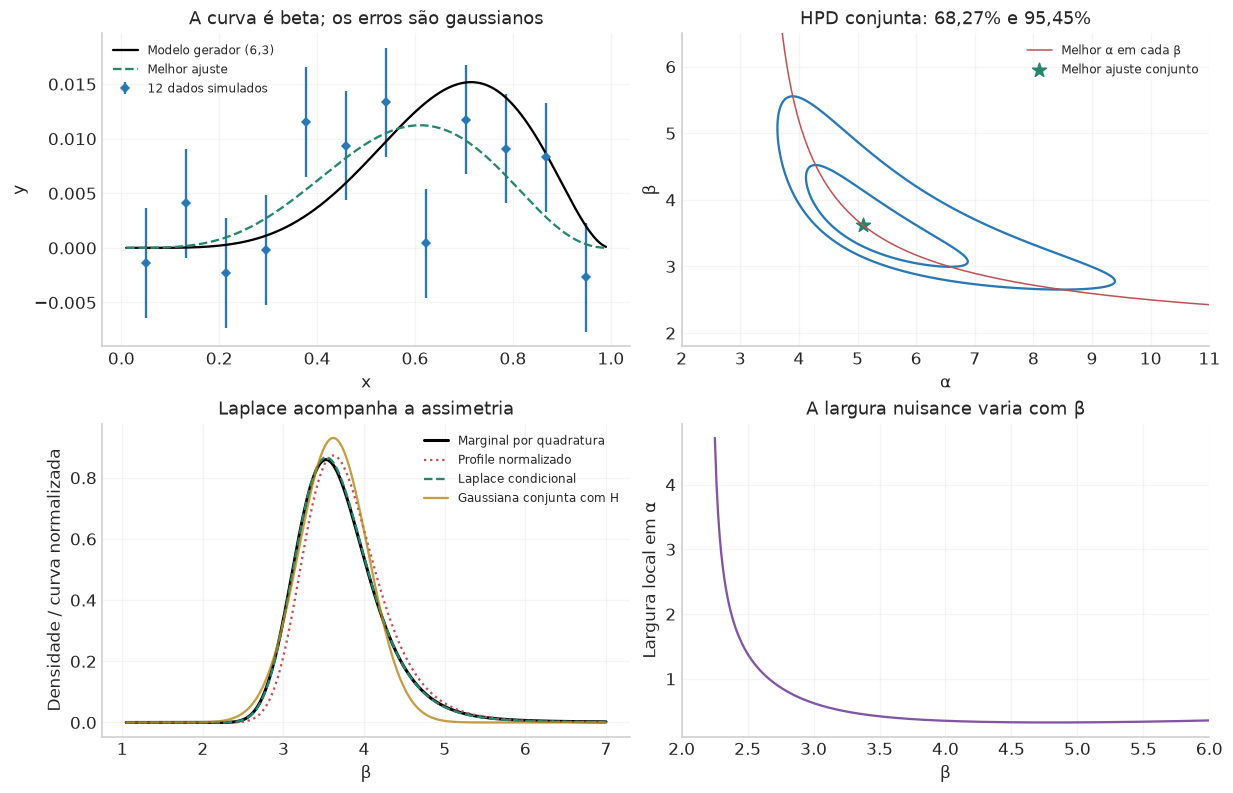

,Parâmetro,Gerador,Melhor ajuste,Desvio gaussiano local
0,α,6.0,5.09522,0.73459
1,β,3.0,3.61787,0.42898


,Método,Moda,Média,Desvio,TV para a marginal
0,Quadratura,3.5252,3.70545,0.54271,0.00000
1,Profile,3.6204,3.78999,0.52395,0.07969
2,Laplace por fatia,3.5252,3.70123,0.52870,0.00578
3,Gaussiana conjunta,3.6204,3.61787,0.42898,0.07827


Massa exata nas fatias sem máximo interior: 3.9e-06.


In [6]:
rng_beta=np.random.default_rng(241110)
x_beta=np.linspace(.05,.95,12);sig_beta=.005
lo_a,hi_a,lo_b,hi_b=1.05,16.,1.05,7.
logs_x=np.column_stack([np.log(x_beta),np.log1p(-x_beta)])
def modelo_beta(a,b,x=x_beta):
    return np.exp((np.asarray(a)[...,None]-1)*np.log(x)+(np.asarray(b)[...,None]-1)*np.log1p(-x))
y_beta=modelo_beta(6.,3.)+rng_beta.normal(0,sig_beta,len(x_beta))
def psi_beta(theta):
    return .5*np.sum(((y_beta-modelo_beta(*theta))/sig_beta)**2)
fit_beta=optimize.minimize(psi_beta,[6.,3.],method='L-BFGS-B',bounds=[(lo_a,hi_a),(lo_b,hi_b)])
verificar('Otimização do modelo beta',fit_beta.success)
best_beta=fit_beta.x;mu_beta=modelo_beta(*best_beta);res_beta=y_beta-mu_beta
J_beta=mu_beta[:,None]*logs_x
K_beta=mu_beta[:,None,None]*np.einsum('ia,ib->iab',logs_x,logs_x)
T_beta=mu_beta[:,None,None,None]*np.einsum('ia,ib,ic->iabc',logs_x,logs_x,logs_x)
F_beta=J_beta.T@J_beta/sig_beta**2
H_beta=F_beta-np.einsum('i,iab->ab',res_beta,K_beta)/sig_beta**2
verificar('Máximo beta tem curvatura positiva',np.linalg.eigvalsh(H_beta).min()>0)
def grid_beta(na,nb):
    av=np.linspace(lo_a,hi_a,na);bv=np.linspace(lo_b,hi_b,nb)
    AA,BB=np.meshgrid(av,bv,indexing='ij')
    pred=modelo_beta(AA,BB)
    lograw=-.5*np.sum(((y_beta-pred)/sig_beta)**2,axis=-1)+fit_beta.fun
    pdf,z=norm2(np.exp(lograw),av,bv)
    return av,bv,AA,BB,pdf,z
gr_beta_coarse=grid_beta(351,251)
a_beta,b_beta,AA_beta,BB_beta,pdf_beta,Z_beta=grid_beta(701,501)
marg_beta=normalizar(trap(pdf_beta,a_beta,axis=0),b_beta)
verificar('Refinamento da integral beta',abs(Z_beta/gr_beta_coarse[-1]-1)<.002)

opt_a=[];logprof_beta=[];Hcond_beta=[];valid_beta=[]
for b in b_beta:
    opt=optimize.minimize_scalar(lambda a:psi_beta([a,b]),bounds=(lo_a,hi_a),method='bounded')
    mu=modelo_beta(opt.x,b);r=y_beta-mu
    h=np.sum((mu*logs_x[:,0])**2-r*mu*logs_x[:,0]**2)/sig_beta**2
    opt_a.append(opt.x);logprof_beta.append(-opt.fun);Hcond_beta.append(h)
    valid_beta.append(h>0 and lo_a+.002<opt.x<hi_a-.002)
opt_a=np.array(opt_a);Hcond_beta=np.array(Hcond_beta);valid_beta=np.array(valid_beta)
logprof_beta=np.array(logprof_beta)
prof_beta=normalizar_log(logprof_beta,b_beta)
lap_raw=np.zeros(len(b_beta))
lap_raw[valid_beta]=np.exp(logprof_beta[valid_beta]+fit_beta.fun)*np.sqrt(2*np.pi/Hcond_beta[valid_beta])
# Como o máximo é interior nas fatias relevantes, só corrigimos a integral gaussiana
# pela fração dentro da prior. Fatias sem máximo interior não recebem a fórmula.
raiz_h=np.sqrt(Hcond_beta[valid_beta])
frac=(stats.norm.cdf((hi_a-opt_a[valid_beta])*raiz_h)
      -stats.norm.cdf((lo_a-opt_a[valid_beta])*raiz_h))
lap_raw[valid_beta]*=frac
lap_beta=normalizar(lap_raw,b_beta)
massa_fatias_invalidas=trap(marg_beta*(~valid_beta),b_beta)
verificar('Fatias sem máximo interior têm massa desprezível',massa_fatias_invalidas<1e-4)
global_beta=normalizar(stats.norm.pdf(b_beta,best_beta[1],np.sqrt(np.linalg.inv(H_beta)[1,1])),b_beta)
fig,ax=plt.subplots(2,2,figsize=(11.1,7.1),constrained_layout=True)
xf=np.linspace(.01,.99,700)
ax[0,0].errorbar(x_beta,y_beta,yerr=sig_beta,fmt='D',ms=4,color=AZUL,label='12 dados simulados')
ax[0,0].plot(xf,modelo_beta(6,3,x=xf),color='black',label='Modelo gerador (6,3)')
ax[0,0].plot(xf,modelo_beta(*best_beta,x=xf),'--',color=VERDE,label='Melhor ajuste')
ax[0,0].set(xlabel='x',ylabel='y',title='A curva é beta; os erros são gaussianos');ax[0,0].legend(fontsize=8)
ax[0,1].contour(a_beta,b_beta,pdf_beta.T,levels=niveis_hpd(pdf_beta,a_beta,b_beta),colors=AZUL)
ax[0,1].plot(opt_a,b_beta,color=VERMELHO,lw=1,label='Melhor α em cada β')
ax[0,1].scatter(*best_beta,color=VERDE,marker='*',s=90,label='Melhor ajuste conjunto')
ax[0,1].set(xlim=(2,11),ylim=(1.8,6.5),xlabel='α',ylabel='β',title='HPD conjunta: 68,27% e 95,45%');ax[0,1].legend(fontsize=8)
ax[1,0].plot(b_beta,marg_beta,color='black',lw=2,label='Marginal por quadratura')
ax[1,0].plot(b_beta,prof_beta,':',color=VERMELHO,label='Profile normalizado')
ax[1,0].plot(b_beta,lap_beta,'--',color=VERDE,label='Laplace condicional')
ax[1,0].plot(b_beta,global_beta,color=OURO,alpha=.8,label='Gaussiana conjunta com H')
ax[1,0].set(xlabel='β',ylabel='Densidade / curva normalizada',title='Laplace acompanha a assimetria');ax[1,0].legend(fontsize=8)
largura=np.where(valid_beta,1/np.sqrt(Hcond_beta),np.nan)
ax[1,1].plot(b_beta,largura,color=ROXO)
ax[1,1].set(xlim=(2,6),xlabel='β',ylabel='Largura local em α',title='A largura nuisance varia com β')
figura(fig,'05_beta_laplace_slides')
tabela(pd.DataFrame({'Parâmetro':['α','β'],'Gerador':[6.,3.],'Melhor ajuste':best_beta,
    'Desvio gaussiano local':np.sqrt(np.diag(np.linalg.inv(H_beta)))}),'beta_ajuste')
tabela(pd.DataFrame([{'Método':nome,**resumo_1d(p,b_beta),'TV para a marginal':tv(p,marg_beta,b_beta)}
    for nome,p in [('Quadratura',marg_beta),('Profile',prof_beta),('Laplace por fatia',lap_beta),('Gaussiana conjunta',global_beta)]]),'beta_marginais')
print(f'Massa exata nas fatias sem máximo interior: {massa_fatias_invalidas:.3g}.')
verificar('Laplace beta reproduz a marginal com boa precisão neste caso',tv(lap_beta,marg_beta,b_beta)<.03)

A distância de variação total usada na tabela é
$\mathrm{TV}(p,q)=\tfrac12\int|p-q|\,d\beta$; zero significa curvas coincidentes. A referência “exata” é a quadratura da likelihood original na prior declarada, com refinamento numérico conferido.

A diferença entre o gerador $(6,3)$ e o melhor ajuste é esperada em uma realização ruidosa. O ganho de Laplace sobre uma gaussiana conjunta vem de refazer a maximização e a largura ao longo de toda a faixa de $\beta$. A concordância é um resultado deste experimento, não uma garantia para qualquer função beta ou qualquer intensidade de ruído.

O código não usa a fórmula de máximo interior em fatias onde ela não se aplica: mede a massa dessas fatias na referência e verifica que é desprezível. O próximo bloco mostra casos em que bordas ou outros modos têm massa importante e precisam ser tratados.

## 6. Onde a aproximação local perde informação?

### Bordas

Se uma forma gaussiana em $\phi$, de centro $\mu_\phi$ e precisão $h$, é integrada apenas em $[a,b]$, sua integral é
$$
f_\mu\sqrt{2\pi/h}\left[
\Phi((b-\mu_\phi)\sqrt h)-\Phi((a-\mu_\phi)\sqrt h)\right],
$$
onde $f_\mu$ é a altura da gaussiana no centro antes do corte. O termo entre colchetes mede a fração dentro do domínio. Se uma borda passa pelo centro e a outra está muito longe, a fração é $1/2$.

Um máximo **restrito na borda** pode ter derivada não nula: não podemos aplicar a expansão de máximo interior como se esse termo linear desaparecesse. No exemplo abaixo, o expoente é exatamente quadrático antes do corte; conhecemos o centro não restrito e usamos a CDF para integrar corretamente.

### Mais de um modo nuisance

Para modos bem separados, a integral pode ser aproximada por uma **soma das contribuições locais**:
$$
m(\theta)\approx\sum_j
g(\theta,\hat\phi_j)
\frac{(2\pi)^{r/2}}{\sqrt{\det H_{\phi\phi,j}}}.
$$
Usar apenas o máximo global da fatia descarta as massas dos demais modos, mesmo que cada um seja quase gaussiano. A soma exige regiões locais sem dupla contagem relevante; não é uma regra para somar gaussianas arbitrariamente sobrepostas.

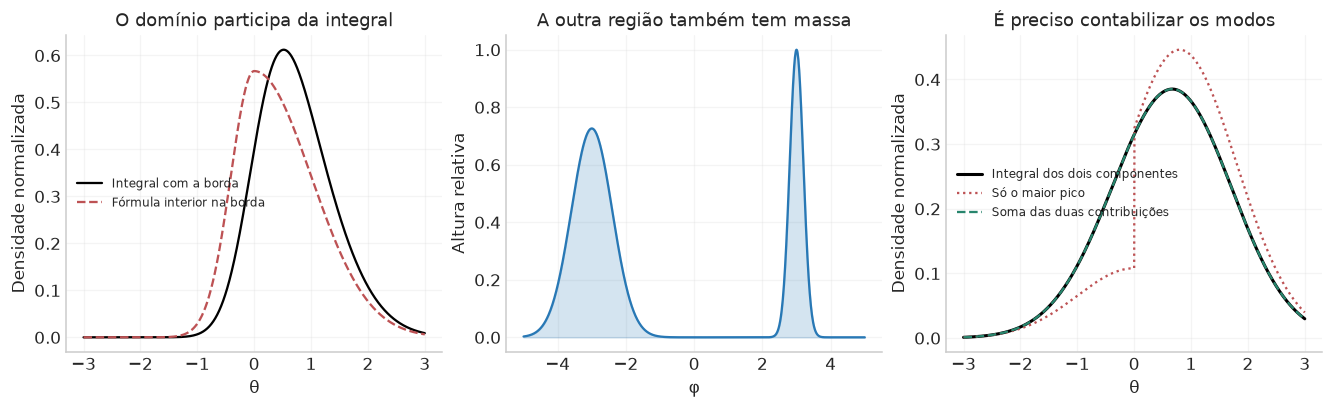

In [7]:
t_falha=np.linspace(-3,3,1201);s_phi=.45
# Modelo gaussiano com prior retangular: θ em [-3,3], φ em [0,5].
fator_corte=stats.norm.cdf((5-t_falha)/s_phi)-stats.norm.cdf(-t_falha/s_phi)
bord_exata=normalizar(np.exp(-t_falha**2/2)*fator_corte,t_falha)
phi_restrita=np.clip(t_falha,0,5)
bord_ingenua=normalizar(np.exp(-t_falha**2/2-(phi_restrita-t_falha)**2/(2*s_phi**2)),t_falha)
verificar('Corte pelo centro guarda metade da gaussiana',np.isclose(stats.norm.cdf(5/s_phi)-.5,.5))

# Duas gaussianas nuisance muito separadas: alturas e larguras distintas.
w1,w2,sep=.2,.6,3.
a_mod=np.exp(.8*t_falha)
m_multi=normalizar(np.exp(-t_falha**2/2)*(w1+a_mod*w2),t_falha)
um_modo=normalizar(np.exp(-t_falha**2/2)*np.where(a_mod>1,a_mod*w2,w1),t_falha)
dois_modos=normalizar(np.exp(-t_falha**2/2)*(w1+a_mod*w2),t_falha)
fig,ax=plt.subplots(1,3,figsize=(12,3.6),constrained_layout=True)
ax[0].plot(t_falha,bord_exata,color='black',label='Integral com a borda')
ax[0].plot(t_falha,bord_ingenua,'--',color=VERMELHO,label='Fórmula interior na borda')
ax[0].set(xlabel='θ',ylabel='Densidade normalizada',title='O domínio participa da integral');ax[0].legend(fontsize=8)
vv=np.linspace(-5,5,900);t0=-.4
slice_mod=np.exp(-(vv-sep)**2/(2*w1*w1))+np.exp(.8*t0)*np.exp(-(vv+sep)**2/(2*w2*w2))
ax[1].plot(vv,slice_mod,color=AZUL);ax[1].fill_between(vv,slice_mod,color=AZUL,alpha=.2)
ax[1].set(xlabel='φ',ylabel='Altura relativa',title='A outra região também tem massa')
ax[2].plot(t_falha,m_multi,color='black',lw=2,label='Integral dos dois componentes')
ax[2].plot(t_falha,um_modo,':',color=VERMELHO,label='Só o maior pico')
ax[2].plot(t_falha,dois_modos,'--',color=VERDE,label='Soma das duas contribuições')
ax[2].set(xlabel='θ',ylabel='Densidade normalizada',title='É preciso contabilizar os modos');ax[2].legend(fontsize=8)
figura(fig,'06_bordas_multimodalidade')
for t0 in [-1.,0.,1.]:
    val=integrate.quad(lambda v:np.exp(-(v-sep)**2/(2*w1*w1))+np.exp(.8*t0)*np.exp(-(v+sep)**2/(2*w2*w2)),-7,7,points=[-sep,sep],epsabs=1e-10)[0]
    esperado=np.sqrt(2*np.pi)*(w1+np.exp(.8*t0)*w2)
    verificar(f'Integração dos dois modos em θ={t0}',np.isclose(val,esperado,rtol=1e-8))

## 7. Efeito de volume da prior: onde a prior entra, exatamente?

Escrevendo a prior como $\pi_0(\theta)\pi_0(\phi\mid\theta)$,
$$
p(\theta\mid D)\propto
\pi_0(\theta)\int\mathcal L(D\mid\theta,\phi)
\pi_0(\phi\mid\theta)\,d\phi.
$$
Essa integral é uma **média da qualidade de ajuste sob os valores nuisance permitidos previamente**. O profile pergunta pelo melhor desses valores. Uma prior plana ainda escolhe uma medida e um domínio: “mesma probabilidade por unidade de $\phi$” é informação, especialmente se a likelihood não determina bem $\phi$.

### 7.1 Um modelo gerador em que podemos fazer toda a conta

Considere $K+1$ medidas, com erros independentes:
$$
D_0=\theta+\varepsilon_0,\quad \varepsilon_0\sim N(0,s^2),
\qquad
D_j=e^{-\kappa\theta}\phi_j+\varepsilon_j,\quad
\varepsilon_j\sim N(0,\sigma^2).
$$
Usaremos o vetor observado $D=(0,\ldots,0)$, prior $\theta\sim U[-3,4]$ e
$\phi_j\overset{\rm ind}{\sim}U[-A,A]$. É um modelo didático de resposta: para $\theta$ maior, o instrumento fica menos sensível às amplitudes nuisance $\phi_j$. A covariância **dos erros observacionais** continua fixa; quem muda é a resposta do modelo.

O melhor ajuste conjunto é $\theta=0,\phi_j=0$. O profile em $\theta$ tem a forma
$$
f(\theta)\propto e^{-\theta^2/(2s^2)}.
$$
A largura da likelihood em cada $\phi_j$ é
$w(\theta)=\sigma e^{\kappa\theta}$. Incluindo explicitamente a prior nuisance,
$$
\begin{aligned}
m(\theta)&\propto e^{-\theta^2/(2s^2)}
\left[\frac1{2A}\int_{-A}^A
e^{-\phi^2/(2w(\theta)^2)}\,d\phi\right]^K\\
&=e^{-\theta^2/(2s^2)}
\left[\frac{\sqrt{2\pi}\,w(\theta)}{2A}
\operatorname{erf}\!\left(\frac{A}{\sqrt2\,w(\theta)}\right)\right]^K.
\end{aligned}
$$
Se \(A\gg w\) em toda a região relevante, o erro de corte é pequeno e
$$
\log m(\theta)=
-\frac{\theta^2}{2s^2}+K\kappa\theta+\text{constante}
=-\frac{(\theta-K\kappa s^2)^2}{2s^2}+\text{constante}.
$$
O máximo marginal fica perto de $K\kappa s^2$, apesar do melhor ajuste conjunto estar em zero. O fator de largura é exatamente o termo de Laplace, pois $H_{\phi\phi}=w^{-2}I_K$ e $1/\sqrt{\det H_{\phi\phi}}=w^K$.

Há dois limites diferentes:

- **Prior larga comparada à largura nuisance:** aparece o fator $w^K$; ampliar ainda mais $A$ só multiplica a marginal por uma constante, que cancela após normalizar.
- **Prior estreita, $A\ll w$:** a likelihood é quase constante no pequeno intervalo permitido e a média nuisance tende a 1. O termo de volume varia pouco.

No segundo limite, a prior mudou a quantidade física de valores nuisance plausíveis. Não houve apenas uma alteração numérica na integração.

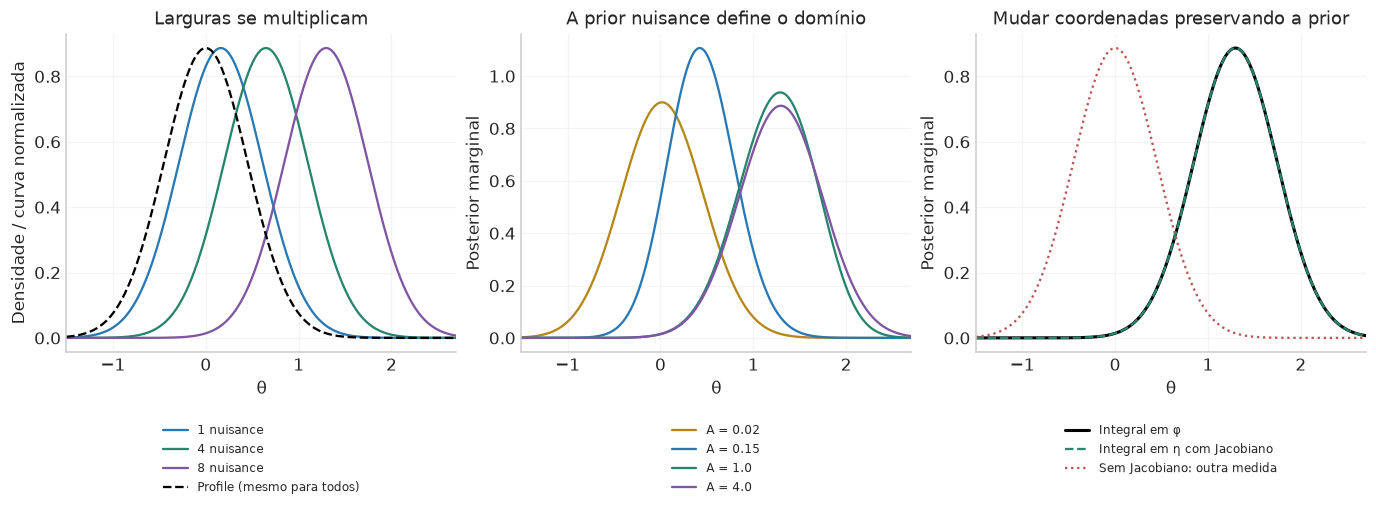

,K,Moda,Média,Desvio,Modo previsto (prior larga),P(θ < 0)
0,1,0.16313,0.162,0.45,0.162,0.35683
1,4,0.64875,0.648,0.45,0.648,0.07396
2,8,1.29625,1.296,0.45,1.296,0.00195


In [8]:
t_vol=np.linspace(-3,4,1601);s_vol=.45;k_vol=.8;sig_vol=.1
def logmassa_vol(t,K,A,sinal=1.):
    w=sig_vol*np.exp(sinal*k_vol*np.asarray(t))
    media_nuis=np.sqrt(2*np.pi)*w/(2*A)*special.erf(A/(np.sqrt(2)*w))
    return -np.asarray(t)**2/(2*s_vol*s_vol)+K*np.log(media_nuis)
prof_vol=normalizar(np.exp(-t_vol**2/(2*s_vol*s_vol)),t_vol)
fig,ax=plt.subplots(1,3,figsize=(12.4,4.5),constrained_layout=True)
vols={}
for K,cor in [(1,AZUL),(4,VERDE),(8,ROXO)]:
    p=normalizar_log(logmassa_vol(t_vol,K,4),t_vol);vols[K]=p
    ax[0].plot(t_vol,p,color=cor,label=f'{K} nuisance')
ax[0].plot(t_vol,prof_vol,'--',color='black',label='Profile (mesmo para todos)')
ax[0].set(xlabel='θ',ylabel='Densidade / curva normalizada',title='Larguras se multiplicam');ax[0].legend(fontsize=8)
for A,cor in [(.02,OURO),(.15,AZUL),(1.,VERDE),(4.,ROXO)]:
    p=normalizar_log(logmassa_vol(t_vol,8,A),t_vol)
    ax[1].plot(t_vol,p,color=cor,label=f'A = {A}')
ax[1].set(xlabel='θ',ylabel='Posterior marginal',title='A prior nuisance define o domínio');ax[1].legend(fontsize=8)

# A mesma medida em coordenadas η_j=φ_j/w(θ) inclui o Jacobiano w(θ)^K.
w_vol=sig_vol*np.exp(k_vol*t_vol);K_coord=8;A_coord=4.
integral_eta=np.sqrt(2*np.pi)*special.erf(A_coord/(np.sqrt(2)*w_vol))
mesma_medida=normalizar(np.exp(-t_vol**2/(2*s_vol*s_vol))*(w_vol*integral_eta/(2*A_coord))**K_coord,t_vol)
sem_jac=normalizar_log(logmassa_vol(t_vol,K_coord,A_coord)-K_coord*np.log(w_vol),t_vol)
ax[2].plot(t_vol,vols[8],color='black',lw=2,label='Integral em φ')
ax[2].plot(t_vol,mesma_medida,'--',color=VERDE,label='Integral em η com Jacobiano')
ax[2].plot(t_vol,sem_jac,':',color=VERMELHO,label='Sem Jacobiano: outra medida')
ax[2].set(xlabel='θ',ylabel='Posterior marginal',title='Mudar coordenadas preservando a prior');ax[2].legend(fontsize=8)
for a in ax:
    a.set_xlim(-1.5,2.7)
    a.legend(loc='upper center',bbox_to_anchor=(.5,-.19),fontsize=8)
figura(fig,'07_prior_volume_explicito')
tabela(pd.DataFrame([{'K':K,**resumo_1d(p,t_vol),'Modo previsto (prior larga)':K*k_vol*s_vol**2,
    'P(θ < 0)':trap(p[t_vol<=0],t_vol[t_vol<=0])} for K,p in vols.items()]),'volume_marginal')
verificar('Jacobiano preserva a marginal exata',tv(mesma_medida,vols[8],t_vol)<1e-10)
verificar('Predição analítica do deslocamento de volume',abs(resumo_1d(vols[8],t_vol)['Moda']-8*k_vol*s_vol**2)<.01)

### 7.2 Coordenadas, “viés” e interpretação

Na mudança $\eta_j=\phi_j/w(\theta)$, temos $d^K\phi=w(\theta)^K d^K\eta$. A prior transformada tem esse Jacobiano e limites $|\eta_j|\leq A/w(\theta)$. **Com a mesma medida de probabilidade, a marginal é invariável.** Declarar novamente uma prior plana nas novas coordenadas, ou omitir o Jacobiano, define outro problema de inferência.

Uma diferença entre MAP conjunto e moda marginal não demonstra um erro de marginalização: são resumos distintos. Tampouco demonstra, sozinha, viés estatístico frequentista; essa propriedade envolve uma esperança sobre dados repetidos e um estimador especificado. O problema interpretativo surge quando tratamos uma massa posterior integrada como se ela medisse exclusivamente a melhor qualidade de ajuste.

Também não se pode “corrigir” o volume apagando o determinante e ainda afirmar que calculamos a mesma marginal. Laplace **inclui** o volume em sua aproximação. Retirar esse termo muda o resumo utilizado; alterar a prior muda o modelo probabilístico.

Os trabalhos citados nos slides examinam precisamente essas diferenças em inferência cosmológica. Hadzhiyska et al. discutem a relação entre Laplace, profile e priors de Jeffreys; a possibilidade de cancelamentos depende do modelo e das hipóteses e não fornece uma regra universal para remover todo efeito de volume. Ried Guachalla et al. avaliam priors mediante critérios de estimador e cobertura em simulações. São escolhas inferenciais que exigem justificativa, além da inspeção de um corner plot.

### 7.3 A conexão com as aparentes tensões dos slides 99–100

No nosso modelo, imagine outro experimento cuja resposta nuisance seja $e^{+\kappa\theta}$. Os dois profiles atingem o máximo em $\theta=0$, mas as marginais podem favorecer lados opostos por suas larguras nuisance. Isso reproduz o mecanismo discutido nos slides, com uma função explícita.

Ter um melhor ajuste comum não basta para provar compatibilidade estatística, assim como comparar apenas posições de marginais não descreve toda a geometria. Uma análise de tensão precisa especificar a estatística, as priors e sua calibração; não atribuímos automaticamente um número de “sigmas de tensão” às curvas abaixo.

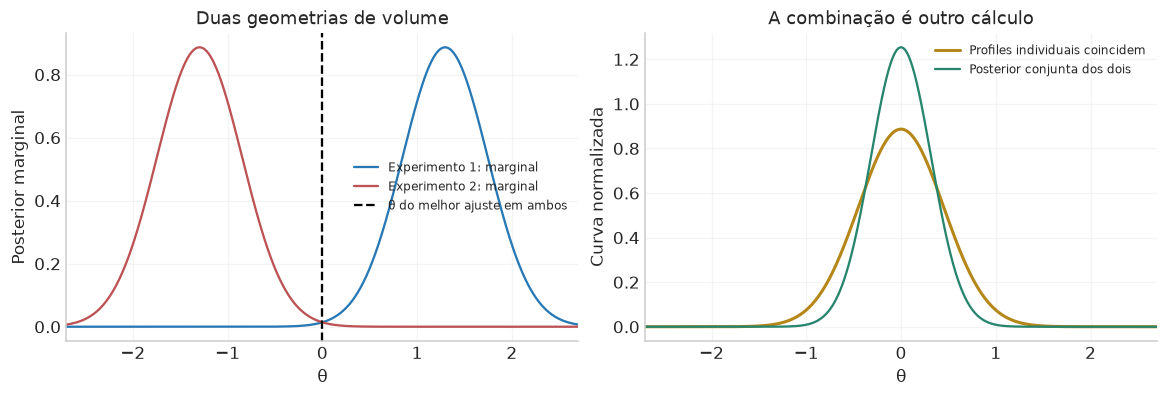

In [9]:
m_exp1=vols[8]
m_exp2=normalizar_log(logmassa_vol(t_vol,8,4,sinal=-1.),t_vol)
# Nuisance independentes entre os dois experimentos; prior comum de θ uniforme.
m_combinada=normalizar(m_exp1*m_exp2,t_vol)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
ax[0].plot(t_vol,m_exp1,color=AZUL,label='Experimento 1: marginal')
ax[0].plot(t_vol,m_exp2,color=VERMELHO,label='Experimento 2: marginal')
ax[0].axvline(0,color='black',ls='--',label='θ do melhor ajuste em ambos')
ax[0].set(xlim=(-2.7,2.7),xlabel='θ',ylabel='Posterior marginal',title='Duas geometrias de volume');ax[0].legend(fontsize=8)
ax[1].plot(t_vol,prof_vol,color=OURO,lw=2,label='Profiles individuais coincidem')
ax[1].plot(t_vol,m_combinada,color=VERDE,label='Posterior conjunta dos dois')
ax[1].set(xlim=(-2.7,2.7),xlabel='θ',ylabel='Curva normalizada',title='A combinação é outro cálculo');ax[1].legend(fontsize=8)
figura(fig,'08_volume_experimentos')

## 8. Por que não fazer uma Taylor qualquer de ordem maior?

Precisamos distinguir duas operações:

1. **Expandir a densidade:** $p(t)\approx p_0+p'_0t+p''_0t^2/2+\cdots$. O polinômio resultante pode ficar negativo. Para uma gaussiana padrão, $p(t)/p(0)\approx1-t^2/2$, negativo quando $|t|>\sqrt2$.
2. **Expandir o logaritmo e exponenciar:** $p(t)\approx p_0e^{q_k(t)}$. A exponencial permanece positiva, mas pode crescer nas caudas e não ser integrável. Uma contribuição cúbica não nula domina com sinais opostos nos dois extremos; uma contribuição quártica de sinal inadequado também pode causar divergência.

Portanto, no slide 102, a dificuldade de uma Taylor de $\log p$ não é produzir valores negativos de $p$: é perder o comportamento que confina a massa. “Positiva definida” pode estar se referindo à forma do expoente, e convém não confundi-la com positividade da densidade.

Veja $\mu(t)=t-t^3/3$, um dado $D=0$ e erro $\sigma=1$:
$$
\Psi_{\rm exata}(t)=\tfrac12\mu(t)^2
=\tfrac12t^2-\tfrac13t^4+\tfrac1{18}t^6.
$$
Uma Taylor de $\log\mathcal L=-\Psi$ até grau 4 elimina o termo que domina e estabiliza as caudas. Reter a previsão cúbica inteira dentro do quadrado conserva esse termo sextico. Os três zeros $t=0,\pm\sqrt3$ aqui são degenerescências **reais** do modelo escolhido, não modos espúrios da aproximação.

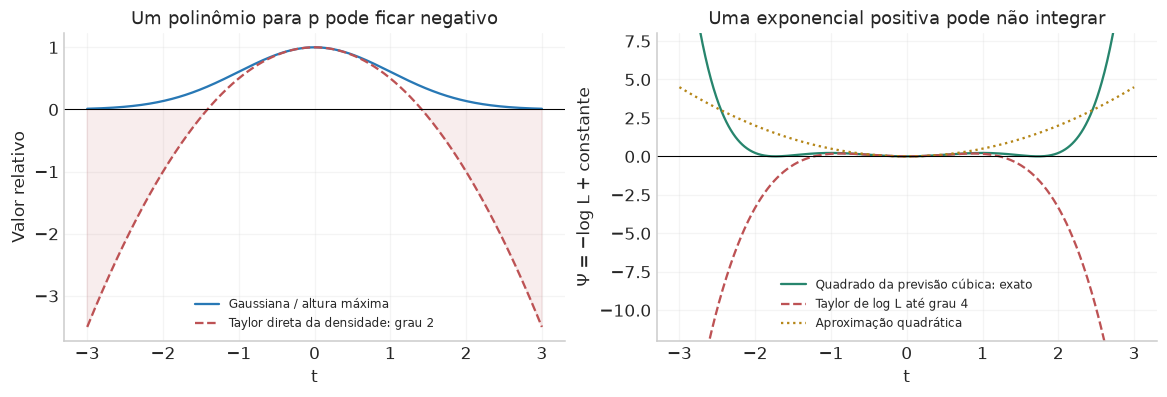

In [10]:
t_taylor=np.linspace(-3,3,1000)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
ax[0].plot(t_taylor,np.exp(-t_taylor**2/2),color=AZUL,label='Gaussiana / altura máxima')
ax[0].plot(t_taylor,1-t_taylor**2/2,'--',color=VERMELHO,label='Taylor direta da densidade: grau 2')
ax[0].axhline(0,color='black',lw=.7);ax[0].fill_between(t_taylor,1-t_taylor**2/2,0,where=abs(t_taylor)>np.sqrt(2),color=VERMELHO,alpha=.1)
ax[0].set(xlabel='t',ylabel='Valor relativo',title='Um polinômio para p pode ficar negativo');ax[0].legend(fontsize=8)
psiex=.5*(t_taylor-t_taylor**3/3)**2
psi4=.5*t_taylor**2-t_taylor**4/3
ax[1].plot(t_taylor,psiex,color=VERDE,label='Quadrado da previsão cúbica: exato')
ax[1].plot(t_taylor,psi4,'--',color=VERMELHO,label='Taylor de log L até grau 4')
ax[1].plot(t_taylor,.5*t_taylor**2,':',color=OURO,label='Aproximação quadrática')
ax[1].axhline(0,color='black',lw=.7)
ax[1].set(xlabel='t',ylabel='Ψ = −log L + constante',ylim=(-12,8),title='Uma exponencial positiva pode não integrar');ax[1].legend(fontsize=8)
figura(fig,'09_duas_taylor')
verificar('Taylor direta da densidade pode ser negativa',(1-t_taylor**2/2).min()<0)

## 9. Slide 104: construir DALI a partir da previsão

Vamos restringir esta dedução à likelihood gaussiana com **covariância dos dados fixa**:
$$
\mathcal L(D\mid\vartheta)=
\frac{\exp[-\Psi(\vartheta)]}{(2\pi)^{N/2}\sqrt{\det C}},
\qquad
\Psi=\tfrac12[D-\mu(\vartheta)]^TW[D-\mu(\vartheta)].
$$
Aqui $N$ é o número de componentes dos dados e $W=C^{-1}$. O $M$ dos slides 103–104 corresponde ao nosso $W$; os $p_\alpha$ daqueles slides são **parâmetros**, enquanto $P$ é uma densidade. Usaremos $\vartheta$ para impedir essa colisão de símbolos.

Escolha um ponto de expansão $\vartheta_0$, defina $\delta=\vartheta-\vartheta_0$, $\mu_0=\mu(\vartheta_0)$, $r_0=D-\mu_0$. As derivadas avaliadas nesse ponto são
$$
J_{ia}=\partial_a\mu_i,\quad
K_{iab}=\partial_a\partial_b\mu_i,\quad
T_{iabc}=\partial_a\partial_b\partial_c\mu_i.
$$
O índice $i$ percorre os dados; $a,b,c$ percorrem os parâmetros. Repetições de índices paramétricos significam somas. Os vetores de deslocamento no **espaço dos dados** são
$$
A_i=J_{ia}\delta_a,\qquad
B_i=\frac12K_{iab}\delta_a\delta_b,\qquad
Q_i=\frac16T_{iabc}\delta_a\delta_b\delta_c.
$$
As letras $A,B,Q$ aqui nomeiam vetores de contribuição e não matrizes de covariância. Portanto,
$$
\mu(\vartheta_0+\delta)\approx\mu_0+A+B+Q.
$$

### 9.1 Primeiro o caso fiducial, para enxergar a reorganização

Se $D=\mu_0$, então $r_0=0$. Esse é o experimento fiducial sem ruído usado em um forecast. Também obtemos a mesma parte dependente dos parâmetros ao tomar a média do **logaritmo** da likelihood sobre ruídos de média zero gerados nesse fiducial; isso não equivale, em geral, a tomar a média da likelihood.

Trunque a previsão em segunda ordem: $\Delta\mu_2=A+B$. Agora faça a multiplicação inteira:
$$
\begin{aligned}
\Psi_2
&=\frac12(A+B)^TW(A+B)\\
&=\frac12 A^TWA+\frac12 A^TWB+\frac12 B^TWA+\frac12 B^TWB\\
&=\frac12 A^TWA+A^TWB+\frac12 B^TWB,
\end{aligned}
$$
pois $W=W^T$ e os termos cruzados são o mesmo escalar.

Substituindo os vetores, aparecem todos os coeficientes do slide:
$$
\boxed{
\begin{aligned}
\Psi_2={}&
\frac12(J_a^TWJ_b)\delta_a\delta_b\\
&+\frac12(J_a^TWK_{bc})\delta_a\delta_b\delta_c\\
&+\frac18(K_{ab}^TWK_{cd})\delta_a\delta_b\delta_c\delta_d.
\end{aligned}}
$$
O primeiro termo é a Fisher, $F_{ab}=J_a^TWJ_b$. O coeficiente cúbico é $1/2$ porque $A^TWB=A^TW(K\delta\delta/2)$. O quártico é $1/8$ porque multiplicamos o $1/2$ externo pelos dois fatores $1/2$ de $B$. A aproximação fica
$$
p_2(\vartheta\mid D)\propto \pi_0(\vartheta)\exp[-\Psi_2(\vartheta)].
$$
Com prior plana, a forma no suporte coincide com a likelihood aproximada. Uma prior não plana continua sendo multiplicada explicitamente.

### 9.2 Como isso reorganiza a Taylor de $\log p$?

Considere um parâmetro, escrevendo as derivadas da previsão como vetores $a,b,c$. No fiducial,
$$
\Delta\mu=a\delta+\tfrac12b\delta^2+\tfrac16c\delta^3+\cdots.
$$
A expansão comum do expoente por **potências de $\delta$** começa como
$$
\Psi=
\tfrac12(a^TWa)\delta^2+
\tfrac12(a^TWb)\delta^3+
\left[\tfrac18 b^TWb+\tfrac16a^TWc\right]\delta^4+\cdots.
$$
Há **dois** tipos de termo de grau 4: derivada segunda vezes segunda, e primeira vezes terceira.

O doublet guarda $J$ e $K$, retém o quadrado completo da previsão assim truncada e, por isso, guarda o termo $b^TWb$ mas não o termo $a^TWc$. O triplet inclui $T$ e também os produtos que ele gera até grau 6. Logo, doublet **não é** “a Taylor completa de $\log p$ até grau 4”. A organização por derivadas escolhe um conjunto diferente de termos em cada truncamento finito.

O $O(3)$ ao final da fórmula do slide 104 indica a classe seguinte em derivadas do modelo nessa organização; não deve ser lido como um resto comum de grau cúbico em $\delta$, pois o termo quártico já está presente.

Com a série completa, as duas maneiras de organizar representam a mesma função, quando a série converge. A diferença aparece no critério de **onde interromper**.

### 9.3 Por que isso não equivale a expandir diretamente $p$?

A última operação continua sendo uma exponencial:
$$
p_{\rm DALI}\propto
\pi_0\exp[-\tfrac12\|\Delta\mu_{\rm truncada}\|_W^2],
\qquad \|v\|_W^2=v^TWv.
$$
Não truncamos a Taylor dessa exponencial. Mesmo com $\Psi_2$ polinomial, $e^{-\Psi_2}$ contém infinitas potências de $\delta$.

Para um parâmetro e uma observável, com $W=1$, $a,b,c$ escalares e prior localmente constante, a Taylor **direta da densidade** até grau 4 seria
$$
\frac{p(\delta)}{p(0)}
=1-\frac{a^2}{2}\delta^2-\frac{ab}{2}\delta^3
+\left(\frac{a^4}{8}-\frac{b^2}{8}-\frac{ac}{6}\right)\delta^4+\cdots.
$$
O termo $a^4/8$ vem do quadrado do termo quadrático de $\log p$ dentro da expansão da exponencial. Esses coeficientes não são os do expoente DALI. Assim, há duas decisões distintas: **o que expandir** e **como truncar**. DALI aproxima a previsão e preserva a forma exponencial gaussiana no espaço dos dados.

### 9.4 Singlet, doublet e triplet com uma só regra

| Aproximação | Previsão retida | Expoente completo | Maior grau em $\delta$, no fiducial |
|---|---|---|---|
| Singlet | $A$ | $\tfrac12 A^TWA$ | 2 |
| Doublet | $A+B$ | $\tfrac12(A+B)^TW(A+B)$ | 4 |
| Triplet | $A+B+Q$ | $\tfrac12(A+B+Q)^TW(A+B+Q)$ | 6 |

Abrindo o triplet, além dos três termos do doublet aparecem
$$
A^TWQ+B^TWQ+\tfrac12Q^TWQ,
$$
ou seja,
$$
\frac16(J_a^TWT_{bcd})\delta_a\delta_b\delta_c\delta_d
+\frac1{12}(K_{ab}^TWT_{cde})\delta_a\delta_b\delta_c\delta_d\delta_e
+\frac1{72}(T_{abc}^TWT_{def})\delta_a\delta_b\delta_c\delta_d\delta_e\delta_f.
$$
Os coeficientes $1/6,1/12,1/72$ resultam dos fatores $1/2!$, $1/3!$ e do $1/2$ externo, não de um novo ajuste empírico. A expansão aberta e a forma compacta precisam dar o mesmo valor numérico; vamos conferir isso.

In [11]:
# Conferência independente das multiplicações do slide 104 e do triplet.
rng_alg=np.random.default_rng(25101)
Ralg=rng_alg.normal(size=(5,5));Walg=Ralg.T@Ralg+np.eye(5)
Jalg=rng_alg.normal(size=(5,2));Kalg=rng_alg.normal(size=(5,2,2))
Kalg=(Kalg+Kalg.swapaxes(1,2))/2
Talg=rng_alg.normal(size=(5,2,2,2))
from itertools import permutations
Talg=sum(Talg.transpose((0,)+tuple(i+1 for i in perm)) for perm in permutations(range(3)))/6
delta_alg=rng_alg.normal(size=(100,2))*.3
Aalg=np.einsum('ia,na->ni',Jalg,delta_alg)
Balg=.5*np.einsum('iab,na,nb->ni',Kalg,delta_alg,delta_alg)
Qalg=np.einsum('iabc,na,nb,nc->ni',Talg,delta_alg,delta_alg,delta_alg)/6
def produto_W(a,b):return np.einsum('ni,ij,nj->n',a,Walg,b)
compacta2=.5*produto_W(Aalg+Balg,Aalg+Balg)
aberta2=.5*produto_W(Aalg,Aalg)+produto_W(Aalg,Balg)+.5*produto_W(Balg,Balg)
compacta3=.5*produto_W(Aalg+Balg+Qalg,Aalg+Balg+Qalg)
aberta3=aberta2+produto_W(Aalg,Qalg)+produto_W(Balg,Qalg)+.5*produto_W(Qalg,Qalg)
verificar('Slide 104: forma compacta e aberta',np.allclose(compacta2,aberta2))
verificar('Triplet: todos os termos cruzados',np.allclose(compacta3,aberta3))
verificar('Expoentes fiduciais DALI são não negativos',np.all(compacta2>=0) and np.all(compacta3>=0))
tabela(pd.DataFrame({'Ordem':['Doublet','Triplet'],'Maior diferença numérica':
    [np.max(abs(compacta2-aberta2)),np.max(abs(compacta3-aberta3))]}),'dali_algebra',casas=14)

,Ordem,Maior diferença numérica
0,Doublet,0.000000e+00
1,Triplet,1.000000e-14


**Uma conferência de coeficiente no slide 105:** o produto entre derivadas segundas e terceiras recebe $1/(2!3!)=1/12$. Onde a expressão compactada do slide apresenta $1/6$ nesse produto de grau 5, usamos o coeficiente obtido pela multiplicação acima, consistente com a Eq. (16) de [Sellentin, Quartin & Amendola](https://arxiv.org/html/1401.6892v3). O produto entre derivadas primeiras e terceiras, de grau 4, recebe de fato $1/6$.

### 9.5 Dados observados com ruído: guardar o resíduo

Em uma realização real, $r_0=D-\mu_0$ geralmente não é zero, mesmo se expandirmos no máximo da likelihood. Com $\Delta\mu_k=A+B+\cdots$,
$$
\boxed{\Psi_k=
\tfrac12r_0^TWr_0-r_0^TW\Delta\mu_k
+\tfrac12\Delta\mu_k^TW\Delta\mu_k.}
$$
No máximo de likelihood, $J^TWr_0=0$, então a parte linear em $\delta$ desaparece. Mas $-r_0^TWB$, envolvendo derivadas segundas, pode permanecer e altera a curvatura quadrática:
$$
\Psi_2=\Psi_0+\tfrac12
\left[J_a^TWJ_b-r_0^TWK_{ab}\right]\delta_a\delta_b
+\text{termos de grau maior}.
$$
Recuperamos a curvatura observada da seção 2. Não é correto eliminar todo o resíduo apenas porque estamos no best fit. Em um MAP com prior informativa, até o gradiente da likelihood pode ser não nulo; o gradiente da prior completa a condição de estacionariedade.

Por isso, nos exemplos com ruído usaremos diretamente a forma segura
$\Psi_k=\tfrac12\|D-\mu_k\|_W^2$, com a previsão truncada e a prior explícita. A expressão do slide 104, sem resíduo, é a forma fiducial/forecast. Essa distinção também está na passagem das Eqs. (17)–(19) do artigo original.

## 10. Positividade, normalização e validade são três perguntas

Com $W$ positiva definida e $r_0=0$, o expoente compacto satisfaz $\Psi_k\geq0$; logo $0<e^{-\Psi_k}\leq1$. Para dados ruidosos, o quadrado do resíduo completo também é não negativo. Isso evita a divergência explosiva de uma exponencial com polinômio de sinal inadequado.

Mas uma função positiva e limitada não é automaticamente integrável em um domínio infinito. O produto quártico $(K\delta\delta)^TW(K\delta\delta)$ é **não negativo**, podendo se anular em certas direções. A positividade de $W$ no espaço dos dados não implica confinamento em todas as direções do espaço dos parâmetros.

Um contraexemplo instrutivo, com $C=I$, $D=0$, é
$$
\mu(u,v)=(u,(1-u)v),\qquad
\mathcal L\propto e^{-[u^2+(1-u)^2v^2]/2}.
$$
No ponto $(0,0)$, $J=I$ e $F=I$, positiva definida. O modelo é quadrático: doublet reproduz a likelihood **exata**. Entretanto, para $u\neq1$,
$$
\int_{-\infty}^{\infty}\mathcal L\,dv
\propto\frac{\sqrt{2\pi}e^{-u^2/2}}{|1-u|},
$$
cuja integral em $u$ diverge perto de $u=1$. Nesse ponto o experimento deixa de responder a $v$, e há um vale infinito.

A afirmação de normalização dos slides 103–104 precisa, portanto, de condições globais de confinamento ou de um domínio/prior adequados. **Com uma prior própria**, multiplicar uma likelihood gaussiana de covariância fixa e limitada por essa prior produz integral finita, desde que a integral seja positiva. Uma prior uniforme em domínio infinito não é própria.

Finalmente, mesmo uma aproximação positiva e normalizável pode ser imprecisa: pode distorcer massas, perder modos ou criar modos artificiais. Isso se investiga comparando a previsão, a likelihood original e as marginais.

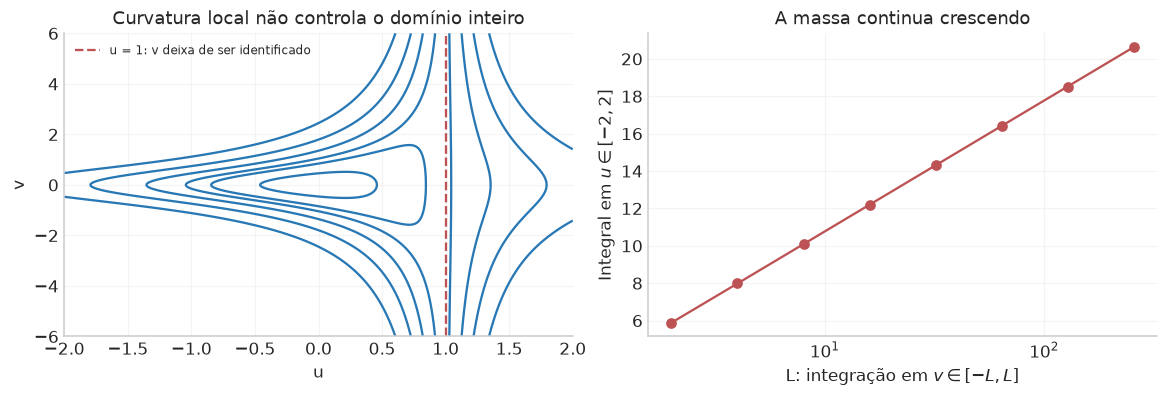

In [12]:
u_bad=np.linspace(-2,2,500);v_bad=np.linspace(-6,6,700)
Ub,Vb=np.meshgrid(u_bad,v_bad,indexing='ij')
L_bad=np.exp(-.5*(Ub**2+(1-Ub)**2*Vb**2))
limites_v=np.array([2.,4.,8.,16.,32.,64.,128.,256.])
integrais_bad=[]
for L in limites_v:
    def integral_v(u):
        a=abs(1-u)
        valor=2*L if a<1e-12 else np.sqrt(2*np.pi)*special.erf(L*a/np.sqrt(2))/a
        return np.exp(-u*u/2)*valor
    integrais_bad.append(integrate.quad(integral_v,-2,2,points=[1],epsabs=1e-9)[0])
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
ax[0].contour(u_bad,v_bad,L_bad.T,levels=[.05,.2,.4,.58,.7,.9],colors=AZUL)
ax[0].axvline(1,color=VERMELHO,ls='--',label='u = 1: v deixa de ser identificado')
ax[0].set(xlabel='u',ylabel='v',title='Curvatura local não controla o domínio inteiro');ax[0].legend(fontsize=8)
ax[1].semilogx(limites_v,integrais_bad,'-o',color=VERMELHO)
ax[1].set(xlabel=r'L: integração em $v\in[-L,L]$',ylabel=r'Integral em $u\in[-2,2]$',title='A massa continua crescendo')
figura(fig,'10_positividade_normalizacao')
verificar('Exemplo não confinado acumula massa com o domínio',np.all(np.diff(integrais_bad)>0))

## 11. Um exemplo em que cada ordem tem um significado visível

Voltamos a duas observáveis gaussianas, agora com
$$
\mu(u,v)=(u,\ v-\kappa u^2-\eta u^3),
\quad D=(0,0),\quad C=\operatorname{diag}(1,s^2),
$$
com $\kappa=0{,}45,\eta=0{,}18,s=0{,}35$.
As previsões truncadas em torno de $(0,0)$ são
$$
\mu_1=(u,v),\quad
\mu_2=(u,v-\kappa u^2),\quad
\mu_3=(u,v-\kappa u^2-\eta u^3).
$$
O singlet faz uma elipse. O doublet acompanha a curvatura quadrática. O triplet recupera a previsão cúbica completa e, **neste modelo**, é exato. Isso não é um teorema de superioridade global do triplet: escolhê-lo aqui permite acompanhar cada contribuição sem derivadas ocultas.

Para normalizar numericamente, declaramos prior uniforme em $[-3{,}5,3{,}5]\times[-5,16]$, comum a todas as curvas. Na versão ideal sem bordas relevantes, a transformação $z=v-\kappa u^2-\eta u^3$ tem Jacobiano 1 e dá
$$
u\sim N(0,1),\quad z\sim N(0,s^2),\quad
v=z+\kappa u^2+\eta u^3.
$$
Usando os momentos gaussianos
$\mathbb E[u^2]=1,\mathbb E[u^4]=3,\mathbb E[u^6]=15$,
$$
\mathbb E[v]=\kappa,\quad
\operatorname{Cov}(u,v)=3\eta,\quad
\operatorname{Var}(v)=s^2+2\kappa^2+15\eta^2.
$$
O termo cúbico muda a correlação global e as caudas de $v$, embora a Fisher no centro continue sendo $\operatorname{diag}(1,s^{-2})$. A geometria local pode deixar essas informações globais de fora.

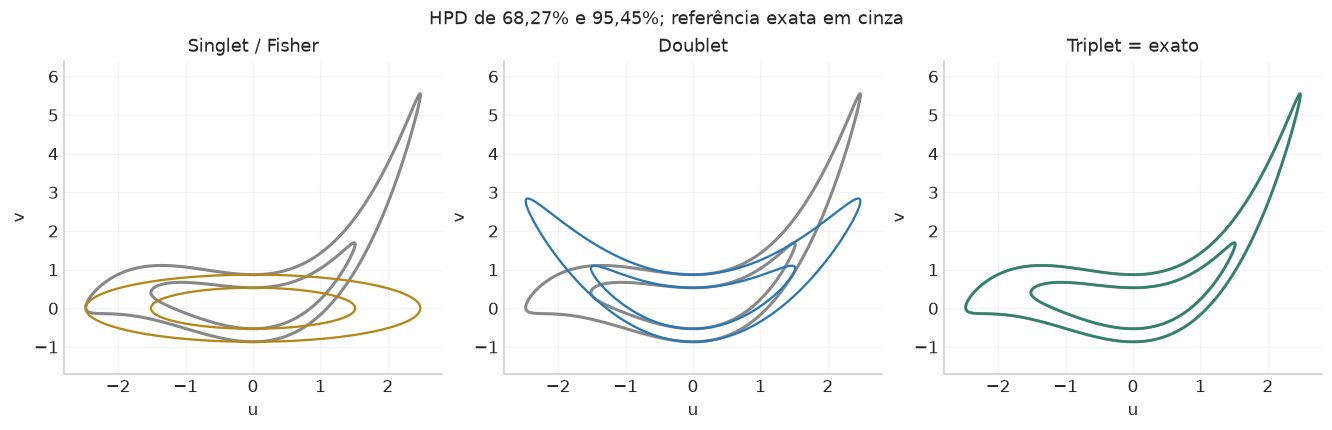

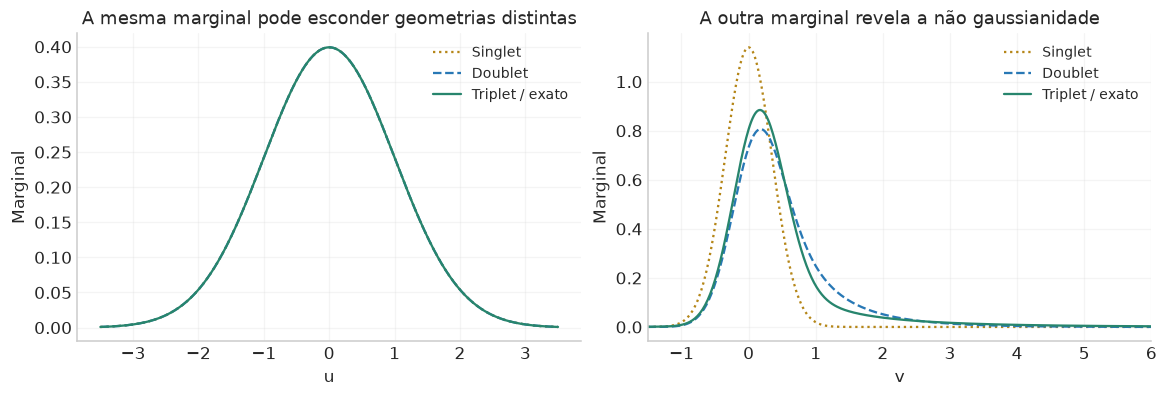

,Aproximação,Moda,Média,Desvio,TV para a marginal exata
0,Singlet,0.00182,0.00000,0.35000,0.26527
1,Doublet,0.17364,0.44725,0.71491,0.07374
2,Triplet,0.17364,0.44725,0.97585,0.00000


In [13]:
u_curva=np.linspace(-3.5,3.5,701);v_curva=np.linspace(-5,16,1101)
Uc,Vc=np.meshgrid(u_curva,v_curva,indexing='ij')
k_curva,eta_curva,s_curva=.45,.18,.35
raw_curva=[
    np.exp(-.5*(Uc**2+(Vc/s_curva)**2)),
    np.exp(-.5*(Uc**2+((Vc-k_curva*Uc**2)/s_curva)**2)),
    np.exp(-.5*(Uc**2+((Vc-k_curva*Uc**2-eta_curva*Uc**3)/s_curva)**2))]
pdf_curva=[norm2(raw,u_curva,v_curva)[0] for raw in raw_curva]
exact_curva=pdf_curva[2]
fig,ax=plt.subplots(1,3,figsize=(12,3.8),constrained_layout=True)
for j,(pdf,lab,cor) in enumerate(zip(pdf_curva,['Singlet / Fisher','Doublet','Triplet = exato'],[OURO,AZUL,VERDE])):
    ax[j].contour(u_curva,v_curva,exact_curva.T,levels=niveis_hpd(exact_curva,u_curva,v_curva),colors='#888888',linewidths=2)
    ax[j].contour(u_curva,v_curva,pdf.T,levels=niveis_hpd(pdf,u_curva,v_curva),colors=cor,linewidths=1.5)
    ax[j].set(xlabel='u',ylabel='v',xlim=(-2.8,2.8),ylim=(-1.7,6.4),title=lab)
fig.suptitle('HPD de 68,27% e 95,45%; referência exata em cinza',fontsize=12)
figura(fig,'11_dali_ordens_geometria')

marg_u_curva=[normalizar(trap(p,v_curva,axis=1),u_curva) for p in pdf_curva]
marg_v_curva=[normalizar(trap(p,u_curva,axis=0),v_curva) for p in pdf_curva]
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
for j,cor,lab in [(0,OURO,'Singlet'),(1,AZUL,'Doublet'),(2,VERDE,'Triplet / exato')]:
    ax[0].plot(u_curva,marg_u_curva[j],color=cor,ls=[':', '--','-'][j],label=lab)
    ax[1].plot(v_curva,marg_v_curva[j],color=cor,ls=[':', '--','-'][j],label=lab)
ax[0].set(xlabel='u',ylabel='Marginal',title='A mesma marginal pode esconder geometrias distintas');ax[0].legend()
ax[1].set(xlabel='v',ylabel='Marginal',xlim=(-1.5,6),title='A outra marginal revela a não gaussianidade');ax[1].legend()
figura(fig,'12_dali_marginalizacao')
tabela(pd.DataFrame([{'Aproximação':lab,**resumo_1d(p,v_curva),
    'TV para a marginal exata':tv(p,marg_v_curva[2],v_curva)}
    for lab,p in zip(['Singlet','Doublet','Triplet'],marg_v_curva)]),'dali_curva_marginais')
verificar('Integração nuisance preserva marginal de u',tv(marg_u_curva[0],marg_u_curva[2],u_curva)<1e-5)

Os contornos coloridos são regiões HPD calculadas com a **massa da própria aproximação**, depois de normalizá-la na prior comum. Não usamos automaticamente os limiares gaussianos de $\Delta\chi^2$ em uma distribuição não gaussiana.

Também não removemos linhas de uma matriz para marginalizar DALI: integramos a densidade aproximada. O atalho de blocos da covariância vale para uma gaussiana conjunta. Neste exemplo, integrar em $v$ é especial porque a dependência em $v$ permanece gaussiana; integrar em $u$ exige uma conta diferente.

## 12. DALI nos mesmos dados ruidosos do modelo beta

As derivadas já calculadas permitem uma comparação sem mudar de dados, ponto de expansão ou prior:
$$
\mu_k(\vartheta)=\mu_0+
J\delta+\frac12K[\delta,\delta]
+\frac16T[\delta,\delta,\delta],
$$
retendo os termos até a ordem escolhida. A notação
$K[\delta,\delta]_i=\sum_{ab}K_{iab}\delta_a\delta_b$
explica a contração implementada no código.

Calcularemos $\exp[-\|D-\mu_k\|^2/(2\sigma^2)]$, incluindo o resíduo real. O máximo da **aproximação** pode aparecer em outro ponto porque, longe do centro, a previsão truncada já é outro modelo. Vamos procurar esse efeito, em vez de pressupor que aumentar a ordem melhora tudo.

A função de contração NumPy einsum implementa as somas escritas acima. Na contração de $K_{iab}$ com dois deslocamentos, os índices $a,b$ desaparecem pela soma, o índice dos dados $i$ permanece e os eixos iniciais da malha são preservados. Assim construímos a previsão em todos os pontos sem um laço Python para cada par $(\alpha,\beta)$.

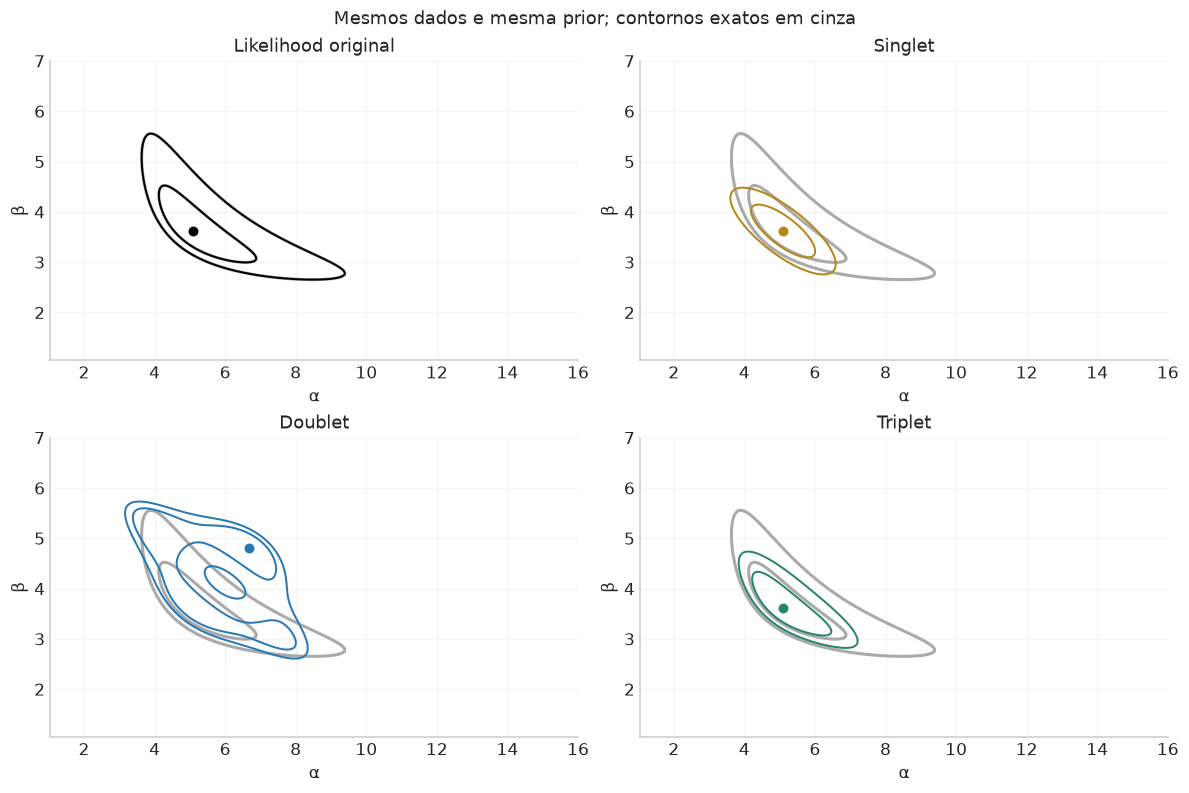

,Ordem,α no máximo da aproximação,β no máximo da aproximação,TV conjunta,TV marginal β
0,Singlet,5.08650,3.6204,0.34482,0.15616
1,Doublet,6.66693,4.8104,0.58359,0.46223
2,Triplet,5.08650,3.6204,0.13973,0.09579


In [14]:
delta_beta=np.stack([AA_beta-best_beta[0],BB_beta-best_beta[1]],axis=-1)
A_beta=np.einsum('ia,...a->...i',J_beta,delta_beta)
B_beta=.5*np.einsum('iab,...a,...b->...i',K_beta,delta_beta,delta_beta)
Q_beta=np.einsum('iabc,...a,...b,...c->...i',T_beta,delta_beta,delta_beta,delta_beta)/6
preds_beta=[mu_beta+A_beta,mu_beta+A_beta+B_beta,mu_beta+A_beta+B_beta+Q_beta]
pdfs_dali_beta=[]
for pred in preds_beta:
    logapp=-.5*np.sum(((y_beta-pred)/sig_beta)**2,axis=-1)
    pdf,_=norm2(np.exp(logapp-np.max(logapp)),a_beta,b_beta)
    pdfs_dali_beta.append(pdf)
fig,ax=plt.subplots(2,2,figsize=(10.7,7.1),constrained_layout=True)
for a,pdf,lab,cor in zip(ax.ravel(),[pdf_beta]+pdfs_dali_beta,
    ['Likelihood original','Singlet','Doublet','Triplet'],['black',OURO,AZUL,VERDE]):
    a.contour(a_beta,b_beta,pdf_beta.T,levels=niveis_hpd(pdf_beta,a_beta,b_beta),colors='#aaaaaa',linewidths=2)
    a.contour(a_beta,b_beta,pdf.T,levels=niveis_hpd(pdf,a_beta,b_beta),colors=cor,linewidths=1.3)
    idx=np.unravel_index(np.argmax(pdf),pdf.shape)
    a.scatter(a_beta[idx[0]],b_beta[idx[1]],color=cor,s=30)
    a.set(xlabel='α',ylabel='β',xlim=(lo_a,hi_a),ylim=(lo_b,hi_b),title=lab)
fig.suptitle('Mesmos dados e mesma prior; contornos exatos em cinza',fontsize=12)
figura(fig,'13_dali_beta_dados_reais')
regs_dali_beta=[]
for lab,pdf in zip(['Singlet','Doublet','Triplet'],pdfs_dali_beta):
    idx=np.unravel_index(np.argmax(pdf),pdf.shape)
    m_beta_app=normalizar(trap(pdf,a_beta,axis=0),b_beta)
    tvjoint=.5*trap(trap(abs(pdf-pdf_beta),b_beta,axis=1),a_beta)
    regs_dali_beta.append({'Ordem':lab,'α no máximo da aproximação':a_beta[idx[0]],
        'β no máximo da aproximação':b_beta[idx[1]],'TV conjunta':tvjoint,
        'TV marginal β':tv(m_beta_app,marg_beta,b_beta)})
tabela(pd.DataFrame(regs_dali_beta),'dali_beta_precision')

# Diferenciação numérica da aproximação de segundo grau da previsão.
# Sua curvatura no centro deve ser a Hessiana observada, incluindo o resíduo.
def psi_dali2_local(delta):
    mu=mu_beta+J_beta@delta+.5*np.einsum('iab,a,b->i',K_beta,delta,delta)
    return .5*np.sum(((y_beta-mu)/sig_beta)**2)
h_num=1e-4;H_num=np.zeros((2,2));zero=np.zeros(2)
for a in range(2):
    ea=np.eye(2)[a]*h_num
    H_num[a,a]=(psi_dali2_local(ea)-2*psi_dali2_local(zero)+psi_dali2_local(-ea))/h_num**2
    for b in range(a):
        eb=np.eye(2)[b]*h_num
        H_num[a,b]=H_num[b,a]=(psi_dali2_local(ea+eb)-psi_dali2_local(ea-eb)-psi_dali2_local(-ea+eb)+psi_dali2_local(-ea-eb))/(4*h_num**2)
verificar('DALI com resíduo recupera H observada no centro',np.allclose(H_num,H_beta,rtol=2e-5,atol=2e-5))

Nesta realização, o doublet pode ser **pior que o singlet** e apresentar um máximo artificial deslocado; a tabela mede isso usando a likelihood original como referência. As derivadas locais estão corretas, inclusive a curvatura no centro. O problema é o prolongamento da previsão truncada por uma região extensa da prior.

O triplet melhora a reconstrução neste caso, mas não há monotonicidade garantida de erros ou de massas entre ordens. A ordem “boa” depende do modelo, do domínio relevante, das coordenadas, do ruído e da informação prévia. Uma aproximação não precisa convergir uniformemente no domínio inteiro apenas porque reproduz mais derivadas em um ponto.

O exemplo também distingue dois usos: **forecast** com dados iguais à previsão fiducial e **análise de uma realização observada**, com resíduo não nulo. Aplicar a expressão fiducial sem conferir essa diferença pode introduzir mais um erro.

## 13. Slide 108: distância ou inverso da distância?

Vamos isolar o mecanismo sem simular uma waveform completa. Para uma fonte de geometria fixa, a amplitude de uma onda gravitacional escala como $h\propto1/d_L$. Inclinação, resposta do detector e demais parâmetros estão fixados neste exemplo; nas inferências reais eles introduzem outras degenerescências.

O mecanismo de bimodalidade artificial em $d_L$, e sua melhora com $1/d_L$, é discutido em de Souza & Quartin, [§2.1 de arXiv:2510.16955](https://arxiv.org/html/2510.16955v2). O exemplo de uma única amplitude abaixo torna essa passagem algébrica explícita.

Escolha unidades em que o dado de amplitude seja $D=1$, a distância fiducial $d_0=1$, a previsão $\mu(d)=1/d$ e o erro gaussiano $\sigma_h=0{,}2$. Para $\delta=d-1$,
$$
\mu(d)=\frac1{1+\delta}
=1-\delta+\delta^2-\delta^3+\cdots,\qquad |\delta|<1.
$$
No doublet, $\mu_2=1-\delta+\delta^2$. Igualar a previsão ao dado dá
$$
\mu_2=1
\ \Longrightarrow\ \delta(\delta-1)=0
\ \Longrightarrow\ d=1\text{ ou }d=2.
$$
O segundo máximo é **espúrio**: a previsão original em $d=2$ é $1/2$, não 1. Ele aparece justamente onde a série local já atingiu a borda de seu raio de convergência. Ter uma exponencial positiva e uma prior própria não conserta esse erro.

Agora use $q=1/d$. A previsão $\mu(q)=q$ é linear e o singlet já representa a likelihood exatamente em $q$.

### 13.1 A mudança de variável precisa carregar a prior

Adotamos a mesma hipótese física $d\sim U[d_{\min},d_{\max}]$, com $d_{\min}=0{,}35,d_{\max}=3$. Como $d=1/q$,
$$
\pi_q(q)=\pi_d(1/q)\left|\frac{dd}{dq}\right|
=\frac{1}{d_{\max}-d_{\min}}q^{-2},
\quad q\in[1/d_{\max},1/d_{\min}].
$$
Transformando a posterior de volta,
$$
p_d(d)=p_q(1/d)\left|\frac{dq}{dd}\right|
=p_q(1/d)d^{-2}.
$$
Os fatores de Jacobiano restauram a mesma posterior. Escolher uma prior plana em $q$ geraria, em vez disso, $\pi_d(d)\propto d^{-2}$: outra prior, outra posterior. A likelihood é uma função escalar dos parâmetros; a **densidade posterior** depende da medida e recebe Jacobianos.

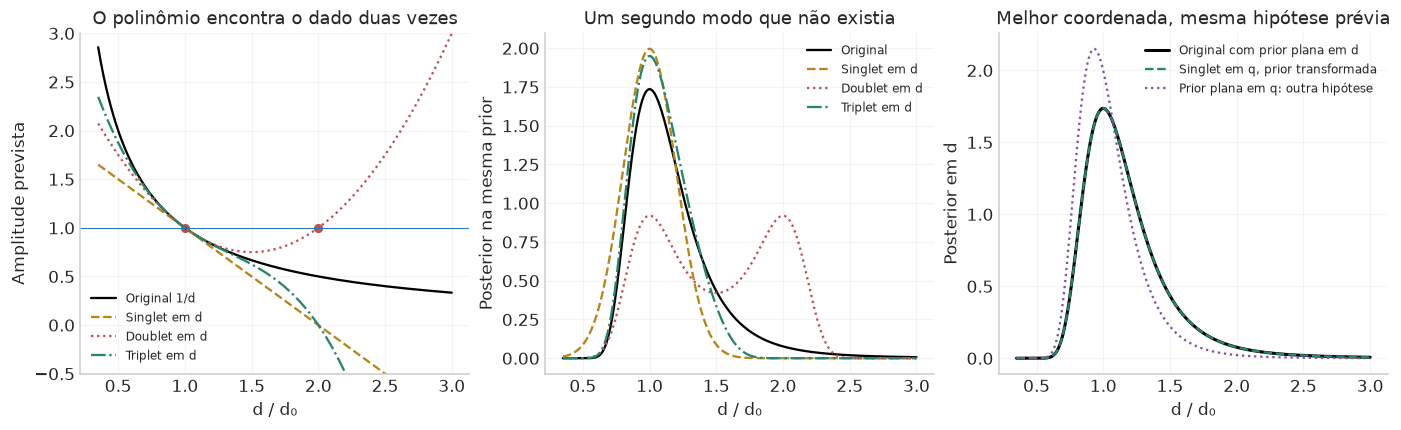

,Aproximação,TV para posterior original
0,Singlet em d,0.20060
1,Doublet em d,0.38250
2,Triplet em d,0.09749
3,Singlet em q com Jacobiano,0.00000


In [15]:
dmin,dmax,s_h=.35,3.,.2
d_gw=np.linspace(dmin,dmax,1601);dd=d_gw-1
pred_gw=[1/d_gw,1-dd,1-dd+dd**2,1-dd+dd**2-dd**3]
like_gw=[np.exp(-.5*((1-mu)/s_h)**2) for mu in pred_gw]
post_gw=[normalizar(L,d_gw) for L in like_gw]
# Singlet em q, com a prior induzida pela mesma prior uniforme em d.
q_grid=np.linspace(1/dmax,1/dmin,2401)
prior_q=q_grid**-2/(dmax-dmin)
post_q=normalizar(np.exp(-.5*((q_grid-1)/s_h)**2)*prior_q,q_grid)
# Avaliar a expressão contínua evita erro de interpolação na comparação.
Zq=trap(np.exp(-.5*((q_grid-1)/s_h)**2)*prior_q,q_grid)
de_volta=np.exp(-.5*((1/d_gw-1)/s_h)**2)*(1/d_gw)**-2/(dmax-dmin)/Zq/d_gw**2
de_volta=normalizar(de_volta,d_gw)
prior_q_plana=normalizar(like_gw[0]/d_gw**2,d_gw)
fig,ax=plt.subplots(1,3,figsize=(12.6,3.8),constrained_layout=True)
for y,lab,cor,ls in zip(pred_gw,['Original 1/d','Singlet em d','Doublet em d','Triplet em d'],
    ['black',OURO,VERMELHO,VERDE],['-','--',':','-.']):
    ax[0].plot(d_gw,y,color=cor,ls=ls,label=lab)
ax[0].axhline(1,color=AZUL,lw=.7);ax[0].scatter([1,2],[1,1],color=VERMELHO,s=25)
ax[0].set(xlabel='d / d₀',ylabel='Amplitude prevista',ylim=(-.5,3),title='O polinômio encontra o dado duas vezes');ax[0].legend(fontsize=8)
for y,lab,cor,ls in zip(post_gw,['Original','Singlet em d','Doublet em d','Triplet em d'],
    ['black',OURO,VERMELHO,VERDE],['-','--',':','-.']):
    ax[1].plot(d_gw,y,color=cor,ls=ls,label=lab)
ax[1].set(xlabel='d / d₀',ylabel='Posterior na mesma prior',title='Um segundo modo que não existia');ax[1].legend(fontsize=8)
ax[2].plot(d_gw,post_gw[0],color='black',lw=2,label='Original com prior plana em d')
ax[2].plot(d_gw,de_volta,'--',color=VERDE,label='Singlet em q, prior transformada')
ax[2].plot(d_gw,prior_q_plana,':',color=ROXO,label='Prior plana em q: outra hipótese')
ax[2].set(xlabel='d / d₀',ylabel='Posterior em d',title='Melhor coordenada, mesma hipótese prévia');ax[2].legend(fontsize=8)
figura(fig,'14_parametrizacao_distancia')
tabela(pd.DataFrame({'Aproximação':['Singlet em d','Doublet em d','Triplet em d','Singlet em q com Jacobiano'],
    'TV para posterior original':[tv(p,post_gw[0],d_gw) for p in post_gw[1:]]+[tv(de_volta,post_gw[0],d_gw)]}),'gw_parametrizacao')
verificar('Coordenada linear e prior transformada recuperam a posterior',tv(de_volta,post_gw[0],d_gw)<1e-10)
raiz_extra=optimize.brentq(lambda d:1-(d-1)+(d-1)**2-1,1.5,2.5)
verificar('Segundo zero do doublet é artificial',
    np.isclose(raiz_extra,2) and abs(1/raiz_extra-1)>2*s_h)

## 14. O que ganhamos, e o que ainda precisamos calcular?

| Escolha | Ganho principal | Limite que precisa ser conferido |
|---|---|---|
| Fisher / singlet fiducial | Forma quadrática barata; marginais gaussianas analíticas quando a posterior é gaussiana | Curvatura local pode omitir assimetria, caudas e modos |
| Laplace condicional | Reduz a dimensão da integração e conserva uma largura nuisance variável | Depende de máximos, curvaturas, bordas e modos relevantes de cada fatia |
| Doublet DALI | Inclui curvatura do modelo com derivadas até segunda ordem | Pode ser impreciso fora da região local e criar máximos artificiais |
| Triplet DALI | Inclui efeitos de derivadas terceiras e seus produtos | Mais derivadas e contrações; não garante melhoria uniforme |
| Integração / amostragem da likelihood original | Referência para verificar a aproximação | Custo de recalcular o modelo ao explorar os parâmetros |

### 14.1 Custo: pré-calcular derivadas não elimina toda integração

Com $k$ parâmetros e derivadas simétricas, há $k$ vetores de derivadas primeiras,
$k(k+1)/2$ de segundas e $k(k+1)(k+2)/6$ de terceiras. Calcular esses vetores pode ser caro. Depois de contrair seus produtos com $W$, muitas avaliações da aproximação ficam baratas e deixam de chamar o modelo físico completo.

Isso é diferente de afirmar que DALI é sempre mais rápido que qualquer grid ou MCMC: depende do custo das derivadas, da dimensão e da precisão desejada. Para os nossos modelos baratos, a vantagem principal é didática e geométrica.

DALI é uma **aproximação da likelihood**, enquanto grid e MCMC são maneiras de integrar/explorar uma função. Podemos aplicar um grid ou um MCMC à própria aproximação DALI. Em geral suas marginais continuam exigindo integração numérica; a redução à eliminação de blocos matriciais é especial da gaussiana.

### 14.2 Priors e inversões: o alcance das afirmações do slide 109

O singlet fiducial usa a mesma likelihood quadrática de Fisher. Podemos multiplicá-la por uma prior **não gaussiana** e integrar numericamente. Portanto, priors gerais não são matematicamente proibidas na aproximação de Fisher; o que se perde é a facilidade de obter uma posterior gaussiana por soma de precisões.

Também não precisamos inverter $F$ apenas para avaliar $\exp[-\delta^TF\delta/2]$. A inversa aparece ao pedir a covariância gaussiana. DALI pode evitar essa etapa no fluxo de avaliação, mas a estabilidade das derivadas, das contrações e da integração ainda precisa ser verificada.

No espaço dos dados, para calcular $r^TC^{-1}r$, é preferível resolver um sistema a formar $C^{-1}$ explicitamente. Se $C=L_C L_C^T$, com $L_C$ seu fator triangular de Cholesky, resolvemos $L_C z=r$; então
$$
r^TC^{-1}r=z^Tz.
$$
Aqui $r$ é o vetor de resíduos, $C$ é a covariância dos erros, $L_C$ é uma raiz matricial dessa covariância e $z$ são os resíduos com covariância unitária. A igualdade segue de $C^{-1}=L_C^{-T}L_C^{-1}$, sem precisar calcular essa inversa no código.

No nosso exemplo de dados independentes, isso já foi feito ao dividir cada resíduo por $\sigma$.

### 14.3 Critério prático de uso

Antes de interpretar a aproximação, identifique a distribuição geradora dos dados, a prior e o ponto de expansão. Verifique o tamanho dos termos omitidos ao longo da região de massa relevante; compare previsões e log-likelihoods originais em pontos dessa região e em eventuais novos máximos. Use a mesma prior nas comparações, inclua os Jacobianos ao mudar de parâmetros e compare **marginais e massas**, além do aspecto dos contornos.

Uma parametrização útil torna o modelo aproximadamente linear na região que os dados e a prior permitem explorar. Reescalar unidades melhora o condicionamento; uma transformação não linear pode mudar a qualidade do truncamento. Nenhuma dessas escolhas dispensa a comparação com o modelo original.

## 15. Ligações que ficam deste bloco

- O **máximo** descreve a maior altura, a **curvatura** descreve uma vizinhança e a **integral** acumula volume.
- A marginal de Laplace é profile **vezes largura efetiva**, com hipóteses condicionais que precisam ser verificadas.
- Uma prior plana continua definindo uma medida. Efeito de volume não é um erro automático de Bayes, nem pode ser apagado mantendo a mesma marginal.
- DALI preserva o quadrado de uma previsão truncada **dentro da exponencial**. Não é uma Taylor direta da densidade, nem um truncamento comum por grau do logaritmo.
- Precisão local, positividade e normalização global são propriedades diferentes. Os exemplos mostram tanto sucesso quanto falha de aproximações.
